In [1]:
import sys 
import platform

print("versione python", sys.version)
print ("sistema operativo :", platform.system(), platform.release())
print("architettura", platform.machine())

versione python 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
sistema operativo : Windows 11
architettura AMD64


In [ ]:
import os
import sys
import json 
import time
import random
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import  accuracy_score

import tensorflow as tf

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)



NumPy: 2.4.4
Pandas: 3.0.6
Scikit-learn: 1.8.0
TensorFlow: 2.21.0


In [3]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Seed impostato:", SEED)

Seed impostato: 42


In [5]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU rilevata:")
    for gpu in gpus:
        print(" -", gpu)
else:
    print("Nessuna GPU rilevata. TensorFlow utilizzerà la CPU.")

Nessuna GPU rilevata. TensorFlow utilizzerà la CPU.


In [7]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"
LOGS_DIR = RESULTS_DIR / "logs"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

directories = [
    RESULTS_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    LOGS_DIR,
    MODELS_DIR,
    REPORTS_DIR
]

for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)

print("Radice del progetto:", PROJECT_ROOT)
print("Cartella dei grafici:", FIGURES_DIR)
print("Cartella delle metriche:", METRICS_DIR)
print("Cartella dei modelli:", MODELS_DIR)

Radice del progetto: c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new
Cartella dei grafici: c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures
Cartella delle metriche: c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics
Cartella dei modelli: c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models


In [8]:
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

print("Dataset caricato correttamente.")

c:\Users\Msi\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


Dataset caricato correttamente.


In [9]:
print("Forma x_train_full:", x_train_full.shape)
print("Forma y_train_full:", y_train_full.shape)

print("Forma x_test:", x_test.shape)
print("Forma y_test:", y_test.shape)

Forma x_train_full: (50000, 32, 32, 3)
Forma y_train_full: (50000, 1)
Forma x_test: (10000, 32, 32, 3)
Forma y_test: (10000, 1)


In [10]:
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

print("Nuova forma y_train_full:", y_train_full.shape)
print("Nuova forma y_test:", y_test.shape)

Nuova forma y_train_full: (50000,)
Nuova forma y_test: (10000,)


In [11]:
assert x_train_full.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)

assert y_train_full.shape == (50000,)
assert y_test.shape == (10000,)

assert set(np.unique(y_train_full)) == set(range(10))
assert set(np.unique(y_test)) == set(range(10))

print("Tutti i controlli strutturali sono stati superati.")

Tutti i controlli strutturali sono stati superati.


In [12]:
print("Tipo delle immagini di training:", x_train_full.dtype)
print("Tipo delle immagini di test:", x_test.dtype)

print("Pixel minimo nel training:", x_train_full.min())
print("Pixel massimo nel training:", x_train_full.max())

print("Pixel minimo nel test:", x_test.min())
print("Pixel massimo nel test:", x_test.max())

Tipo delle immagini di training: uint8
Tipo delle immagini di test: uint8
Pixel minimo nel training: 0
Pixel massimo nel training: 255
Pixel minimo nel test: 0
Pixel massimo nel test: 255


In [13]:
CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

CLASS_NAMES_IT = [
    "aeroplano",
    "automobile",
    "uccello",
    "gatto",
    "cervo",
    "cane",
    "rana",
    "cavallo",
    "nave",
    "camion"
]

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"Classe {class_id}: "
        f"{class_name} - {CLASS_NAMES_IT[class_id]}"
    )

Classe 0: airplane - aeroplano
Classe 1: automobile - automobile
Classe 2: bird - uccello
Classe 3: cat - gatto
Classe 4: deer - cervo
Classe 5: dog - cane
Classe 6: frog - rana
Classe 7: horse - cavallo
Classe 8: ship - nave
Classe 9: truck - camion


fase 1 blocco 2 -analisi esplorativa

In [18]:
train_counts = np.bincount(
    y_train_full,
    minlength=len(CLASS_NAMES)
)

test_counts = np.bincount(
    y_test,
    minlength=len(CLASS_NAMES)
)

print("Distribuzione del training ufficiale:\n")

for class_id, class_name in enumerate(CLASS_NAMES):
    class_name_it = CLASS_NAMES_IT[class_id]
    train_count = train_counts[class_id]

    print(
        f"{class_id:2d} | "
        f"{class_name:<10} | "
        f"{class_name_it:<10} | "
        f"{train_count:5d}"
    )

print("\nDistribuzione del test ufficiale:\n")

for class_id, class_name in enumerate(CLASS_NAMES):
    class_name_it = CLASS_NAMES_IT[class_id]
    test_count = test_counts[class_id]

    print(
        f"{class_id:2d} | "
        f"{class_name:<10} | "
        f"{class_name_it:<10} | "
        f"{test_count:5d}"
    )

Distribuzione del training ufficiale:

 0 | airplane   | aeroplano  |  5000
 1 | automobile | automobile |  5000
 2 | bird       | uccello    |  5000
 3 | cat        | gatto      |  5000
 4 | deer       | cervo      |  5000
 5 | dog        | cane       |  5000
 6 | frog       | rana       |  5000
 7 | horse      | cavallo    |  5000
 8 | ship       | nave       |  5000
 9 | truck      | camion     |  5000

Distribuzione del test ufficiale:

 0 | airplane   | aeroplano  |  1000
 1 | automobile | automobile |  1000
 2 | bird       | uccello    |  1000
 3 | cat        | gatto      |  1000
 4 | deer       | cervo      |  1000
 5 | dog        | cane       |  1000
 6 | frog       | rana       |  1000
 7 | horse      | cavallo    |  1000
 8 | ship       | nave       |  1000
 9 | truck      | camion     |  1000


In [19]:
class_distribution_df = pd.DataFrame({
    "class_id": np.arange(len(CLASS_NAMES)),
    "class_name": CLASS_NAMES,
    "class_name_it": CLASS_NAMES_IT,
    "train_count": train_counts,
    "test_count": test_counts
})

class_distribution_df["total_count"] = (
    class_distribution_df["train_count"]
    + class_distribution_df["test_count"]
)

class_distribution_df["train_percentage"] = (
    class_distribution_df["train_count"]
    / len(y_train_full)
    * 100
)

class_distribution_df["test_percentage"] = (
    class_distribution_df["test_count"]
    / len(y_test)
    * 100
)

class_distribution_df

,class_id,class_name,class_name_it,train_count,test_count,total_count,train_percentage,test_percentage
0,0,airplane,aeroplano,5000,1000,6000,10.0,10.0
1,1,automobile,automobile,5000,1000,6000,10.0,10.0
2,2,bird,uccello,5000,1000,6000,10.0,10.0
3,3,cat,gatto,5000,1000,6000,10.0,10.0
4,4,deer,cervo,5000,1000,6000,10.0,10.0
5,5,dog,cane,5000,1000,6000,10.0,10.0
6,6,frog,rana,5000,1000,6000,10.0,10.0
7,7,horse,cavallo,5000,1000,6000,10.0,10.0
8,8,ship,nave,5000,1000,6000,10.0,10.0
9,9,truck,camion,5000,1000,6000,10.0,10.0


In [20]:
class_distribution_path = (
    METRICS_DIR / "cifar10_class_distribution.csv"
)

class_distribution_df.to_csv(
    class_distribution_path,
    index=False
)

print("Tabella salvata in:")
print(class_distribution_path)

Tabella salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_class_distribution.csv


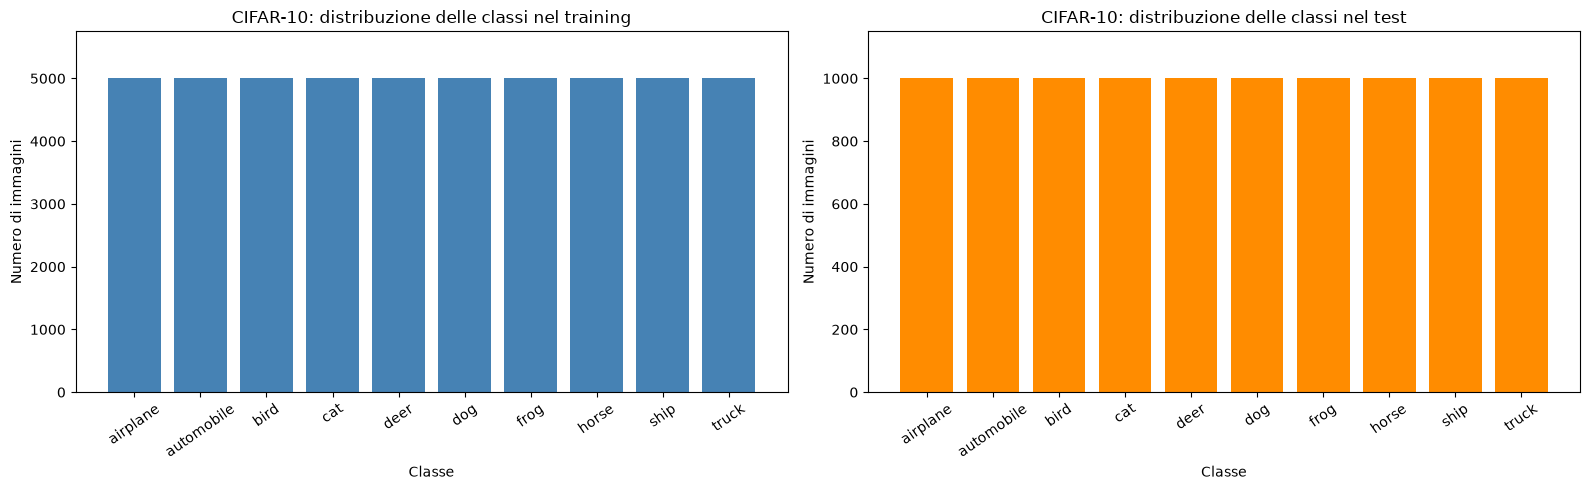

Grafico salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_class_distribution.png


In [21]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 5)
)

axes[0].bar(
    CLASS_NAMES,
    train_counts,
    color="steelblue"
)

axes[0].set_title(
    "CIFAR-10: distribuzione delle classi nel training"
)

axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Numero di immagini")
axes[0].tick_params(
    axis="x",
    rotation=35
)

axes[0].set_ylim(
    0,
    train_counts.max() * 1.15
)

axes[1].bar(
    CLASS_NAMES,
    test_counts,
    color="darkorange"
)

axes[1].set_title(
    "CIFAR-10: distribuzione delle classi nel test"
)

axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Numero di immagini")
axes[1].tick_params(
    axis="x",
    rotation=35
)

axes[1].set_ylim(
    0,
    test_counts.max() * 1.15
)

plt.tight_layout()

distribution_figure_path = (
    FIGURES_DIR / "cifar10_class_distribution.png"
)

plt.savefig(
    distribution_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafico salvato in:")
print(distribution_figure_path)

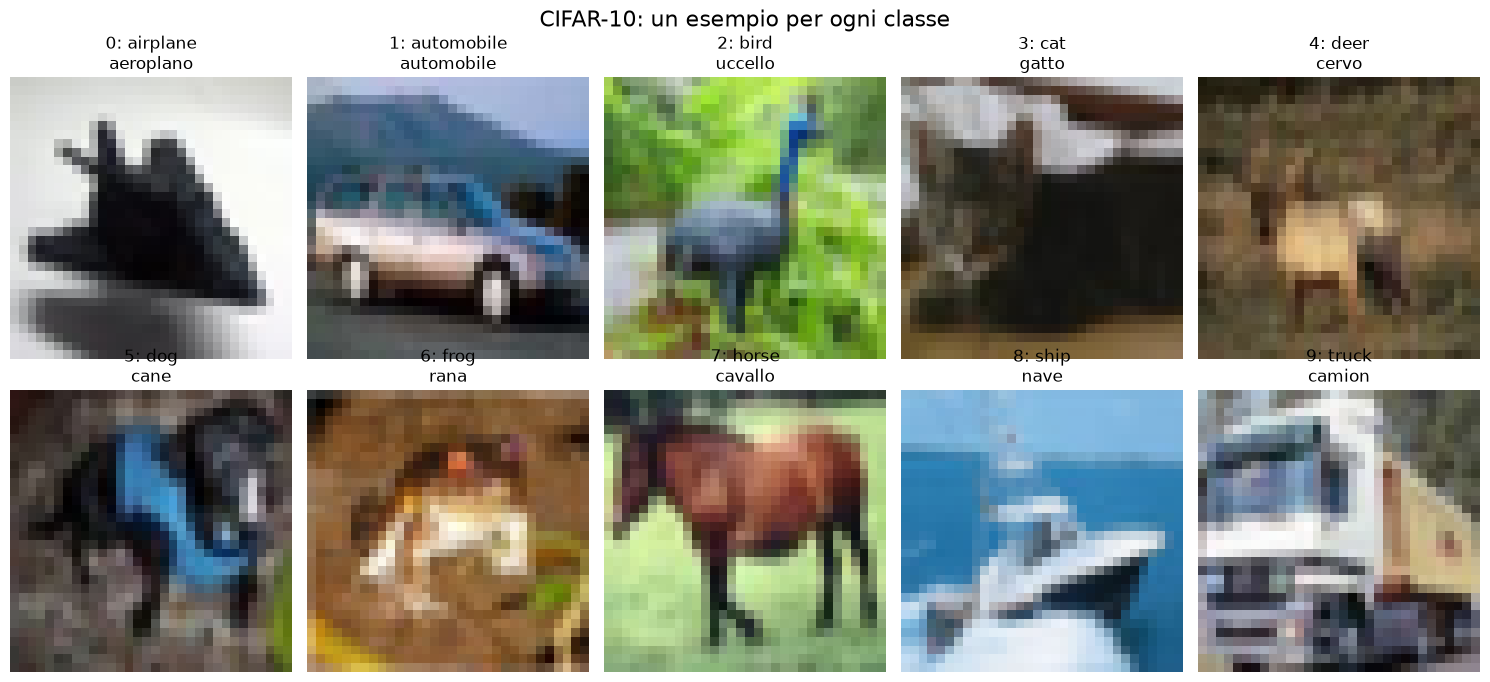

Figura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_one_example_per_class.png


In [22]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(15, 7)
)

axes = axes.ravel()

for class_id in range(len(CLASS_NAMES)):
    class_indices = np.flatnonzero(
        y_train_full == class_id
    )

    selected_index = class_indices[0]

    axes[class_id].imshow(
        x_train_full[selected_index]
    )

    axes[class_id].set_title(
        f"{class_id}: {CLASS_NAMES[class_id]}\n"
        f"{CLASS_NAMES_IT[class_id]}"
    )

    axes[class_id].axis("off")

plt.suptitle(
    "CIFAR-10: un esempio per ogni classe",
    fontsize=16
)

plt.tight_layout()

one_example_path = (
    FIGURES_DIR / "cifar10_one_example_per_class.png"
)

plt.savefig(
    one_example_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figura salvata in:")
print(one_example_path)

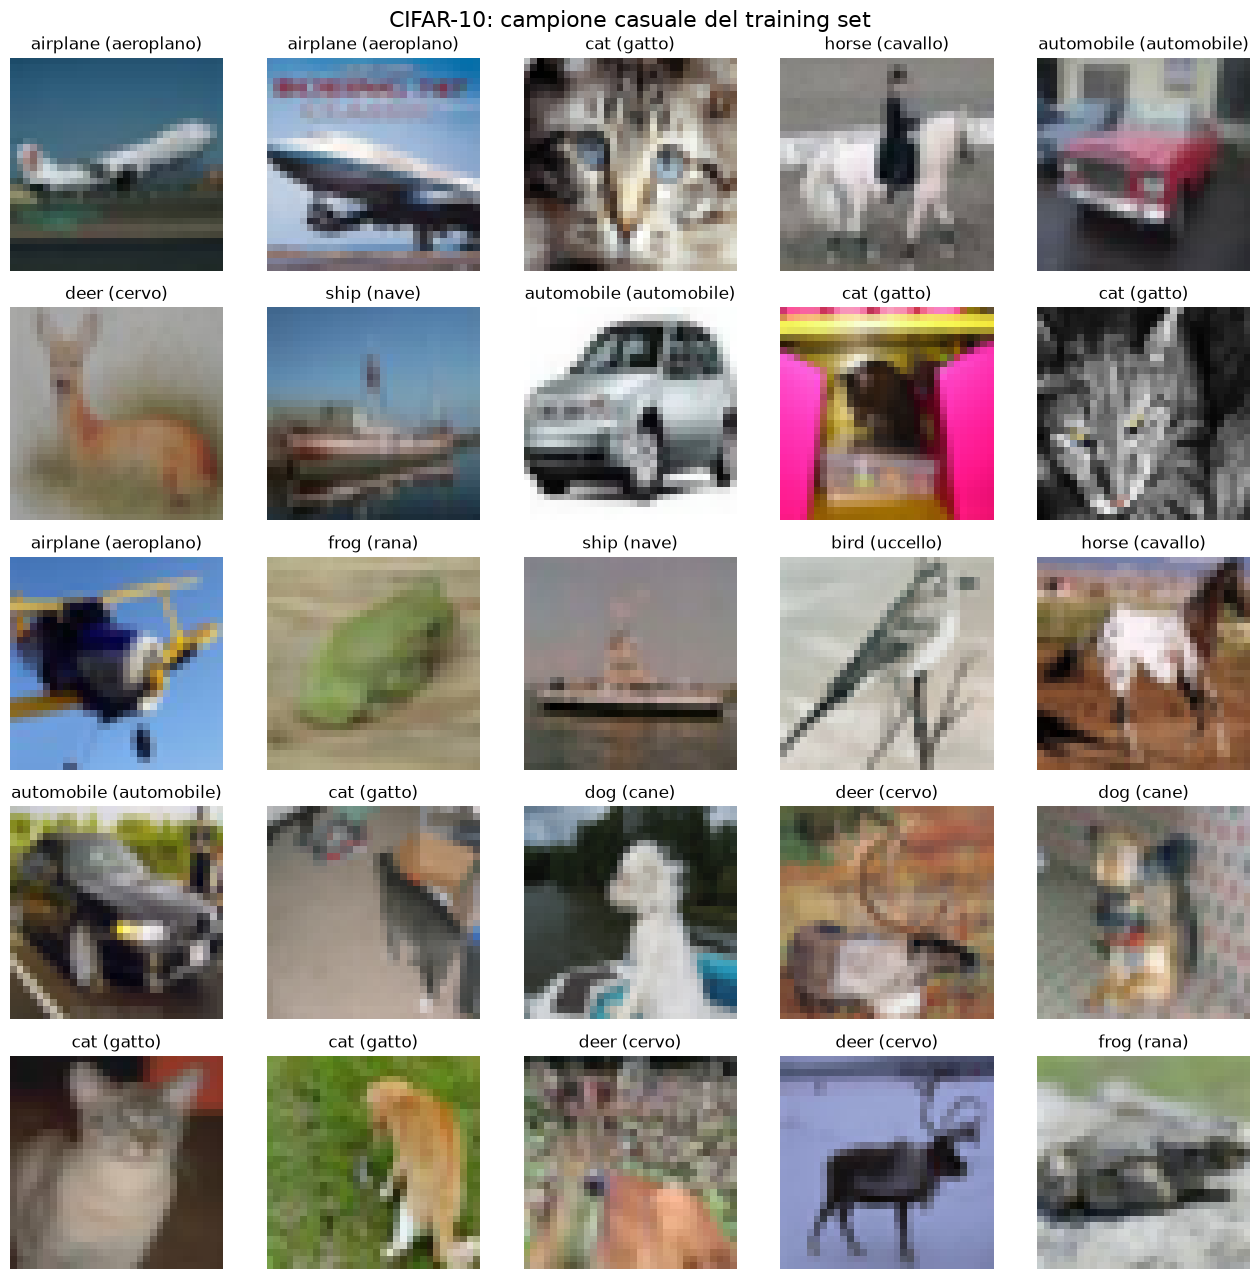

Figura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_random_sample_25.png


In [23]:
rng = np.random.default_rng(SEED)

random_indices = rng.choice(
    len(x_train_full),
    size=25,
    replace=False
)

fig, axes = plt.subplots(
    nrows=5,
    ncols=5,
    figsize=(13, 13)
)

axes = axes.ravel()

for axis, image_index in zip(
    axes,
    random_indices
):
    axis.imshow(
        x_train_full[image_index]
    )

    label = y_train_full[image_index]

    axis.set_title(
        f"{CLASS_NAMES[label]} "
        f"({CLASS_NAMES_IT[label]})"
    )

    axis.axis("off")

plt.suptitle(
    "CIFAR-10: campione casuale del training set",
    fontsize=16
)

plt.tight_layout()

random_sample_path = (
    FIGURES_DIR / "cifar10_random_sample_25.png"
)

plt.savefig(
    random_sample_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figura salvata in:")
print(random_sample_path)

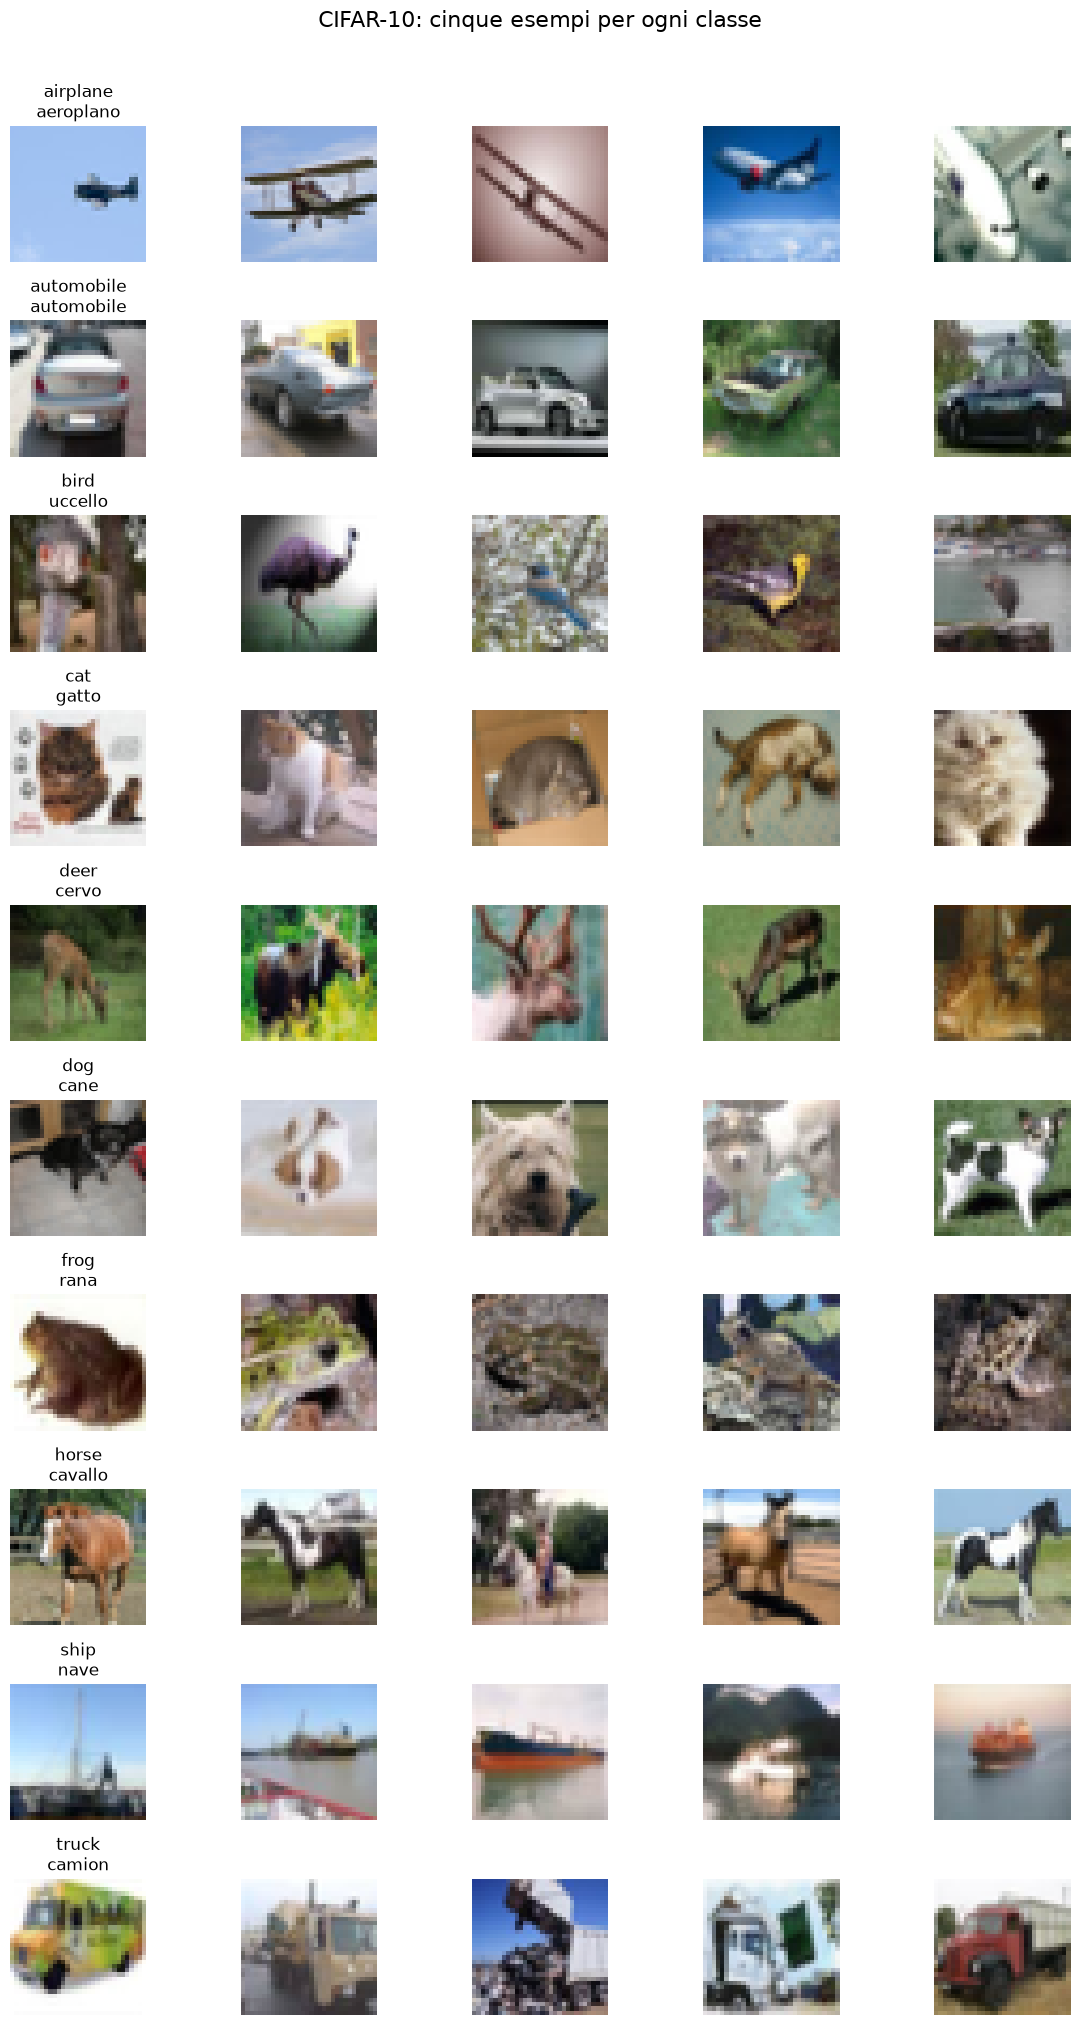

Figura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_five_examples_per_class.png


In [24]:
examples_per_class = 5

fig, axes = plt.subplots(
    nrows=len(CLASS_NAMES),
    ncols=examples_per_class,
    figsize=(12, 20)
)

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    class_indices = np.flatnonzero(
        y_train_full == class_id
    )

    selected_indices = rng.choice(
        class_indices,
        size=examples_per_class,
        replace=False
    )

    for column_id, image_index in enumerate(
        selected_indices
    ):
        axis = axes[class_id, column_id]

        axis.imshow(
            x_train_full[image_index]
        )

        axis.axis("off")

        if column_id == 0:
            axis.set_title(
                f"{class_name}\n"
                f"{CLASS_NAMES_IT[class_id]}"
            )

plt.suptitle(
    "CIFAR-10: cinque esempi per ogni classe",
    fontsize=16,
    y=1.01
)

plt.tight_layout()

examples_grid_path = (
    FIGURES_DIR / "cifar10_five_examples_per_class.png"
)

plt.savefig(
    examples_grid_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figura salvata in:")
print(examples_grid_path)

In [26]:
pixel_statistics = {
    "number_of_images": int(
        x_train_full.shape[0]
    ),
    "height": int(
        x_train_full.shape[1]
    ),
    "width": int(
        x_train_full.shape[2]
    ),
    "channels": int(
        x_train_full.shape[3]
    ),
    "dtype": str(
        x_train_full.dtype
    ),
    "minimum_pixel": int(
        x_train_full.min()
    ),
    "maximum_pixel": int(
        x_train_full.max()
    ),
    "mean_pixel": float(
        x_train_full.mean()
    ),
    "standard_deviation_pixel": float(
        x_train_full.std()
    )
}

pixel_statistics

pixel_statistics_df = pd.DataFrame(
    [pixel_statistics]
)

pixel_statistics_df


pixel_statistics_path = (
    METRICS_DIR / "cifar10_pixel_statistics.csv"
)

pixel_statistics_df.to_csv(
    pixel_statistics_path,
    index=False
)

print("Statistiche salvate in:")
print(pixel_statistics_path)

Statistiche salvate in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_pixel_statistics.csv


In [28]:
x_train_float = (
    x_train_full.astype("float32")
    / 255.0
)

channel_means = x_train_float.mean(
    axis=(0, 1, 2)
)

channel_stds = x_train_float.std(
    axis=(0, 1, 2)
)

rgb_statistics_df = pd.DataFrame({
    "channel": ["Red", "Green", "Blue"],
    "mean": channel_means,
    "standard_deviation": channel_stds
})

rgb_statistics_df

rgb_statistics_path =(
    METRICS_DIR /"cifar10_rgb_statics.csv"
)

rgb_statistics_df.to_csv(
    rgb_statistics_path,
    index=False
)

print("statistiche rgb salvate in :")
print(rgb_statistics_path)

statistiche rgb salvate in :
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_rgb_statics.csv


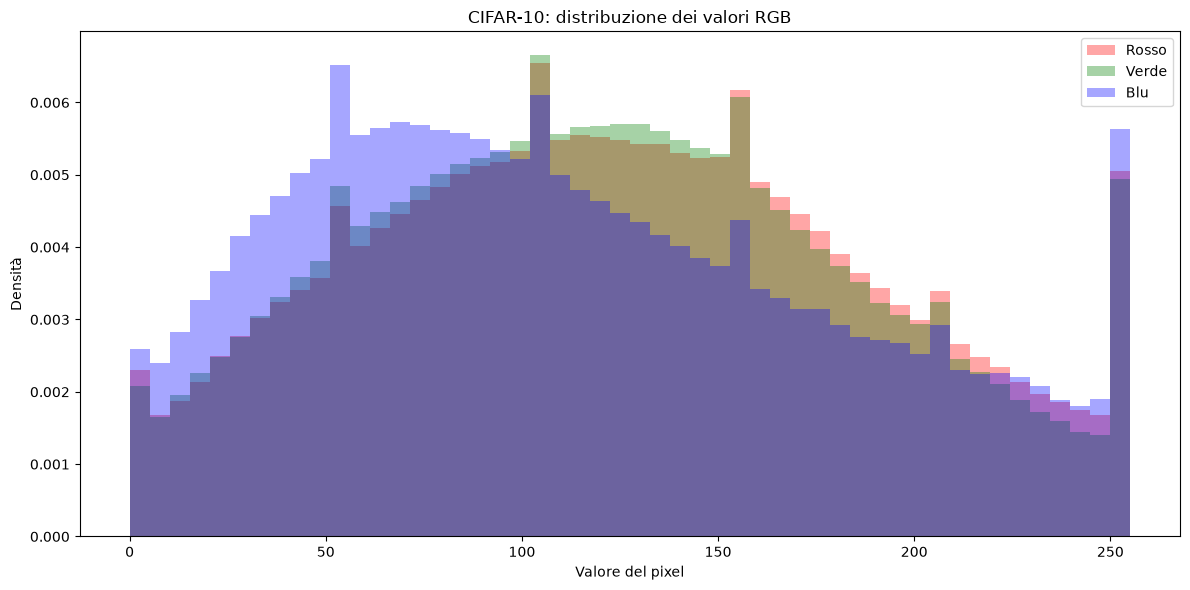

Istogramma salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_rgb_histogram.png


In [29]:
sample_size = 5000

statistics_indices = rng.choice(
    len(x_train_full),
    size=sample_size,
    replace=False
)

pixel_sample = x_train_full[
    statistics_indices
]

channel_colors = [
    "red",
    "green",
    "blue"
]

channel_labels = [
    "Rosso",
    "Verde",
    "Blu"
]

plt.figure(figsize=(12, 6))

for channel_id in range(3):
    plt.hist(
        pixel_sample[:, :, :, channel_id].ravel(),
        bins=50,
        range=(0, 255),
        density=True,
        alpha=0.35,
        color=channel_colors[channel_id],
        label=channel_labels[channel_id]
    )

plt.title(
    "CIFAR-10: distribuzione dei valori RGB"
)

plt.xlabel("Valore del pixel")
plt.ylabel("Densità")
plt.legend()
plt.tight_layout()

rgb_histogram_path = (
    FIGURES_DIR / "cifar10_rgb_histogram.png"
)

plt.savefig(
    rgb_histogram_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Istogramma salvato in:")
print(rgb_histogram_path)

Luminosità media minima: 7.8837890625
Luminosità media massima: 252.296875
Media delle luminosità: 120.7075651236979
Deviazione standard: 31.94263075708578


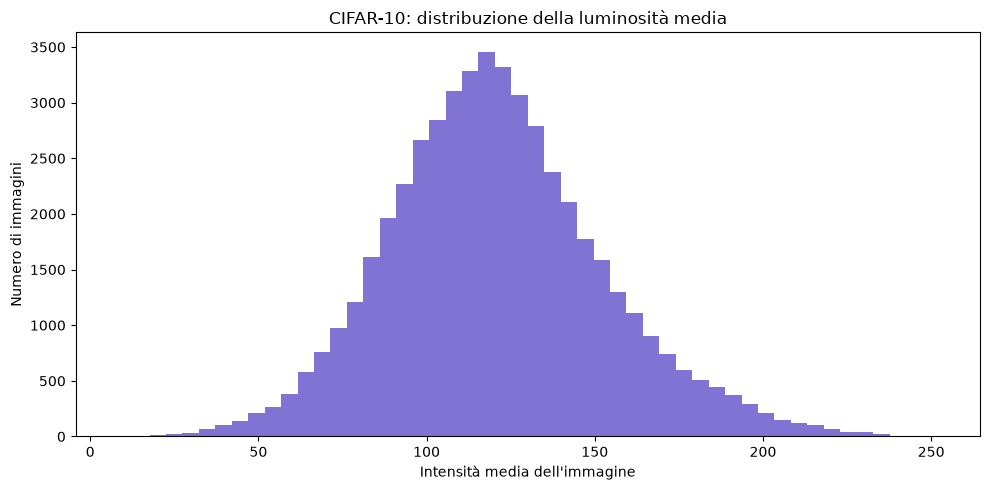

Grafico salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_mean_brightness.png


In [30]:
image_mean_intensity = x_train_full.mean(
    axis=(1, 2, 3)
)

print(
    "Luminosità media minima:",
    image_mean_intensity.min()
)

print(
    "Luminosità media massima:",
    image_mean_intensity.max()
)

print(
    "Media delle luminosità:",
    image_mean_intensity.mean()
)

print(
    "Deviazione standard:",
    image_mean_intensity.std()
)

plt.figure(figsize=(10, 5))

plt.hist(
    image_mean_intensity,
    bins=50,
    color="slateblue",
    alpha=0.85
)

plt.title(
    "CIFAR-10: distribuzione della luminosità media"
)

plt.xlabel(
    "Intensità media dell'immagine"
)

plt.ylabel(
    "Numero di immagini"
)

plt.tight_layout()

brightness_path = (
    FIGURES_DIR / "cifar10_mean_brightness.png"
)

plt.savefig(
    brightness_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafico salvato in:")
print(brightness_path)

In [32]:
image_std = x_train_full.std(
    axis=(1, 2, 3)
)

constant_image_indices = np.flatnonzero(
    image_std == 0
)

print(
    "Numero di immagini completamente costanti:",
    len(constant_image_indices)
)

LOW_VARIANCE_THRESHOLD = 5.0

low_variance_indices = np.flatnonzero(
    image_std < LOW_VARIANCE_THRESHOLD
)

print(
    "Numero di immagini con deviazione standard "
    f"inferiore a {LOW_VARIANCE_THRESHOLD}:",
    len(low_variance_indices)
)

Numero di immagini completamente costanti: 0
Numero di immagini con deviazione standard inferiore a 5.0: 0


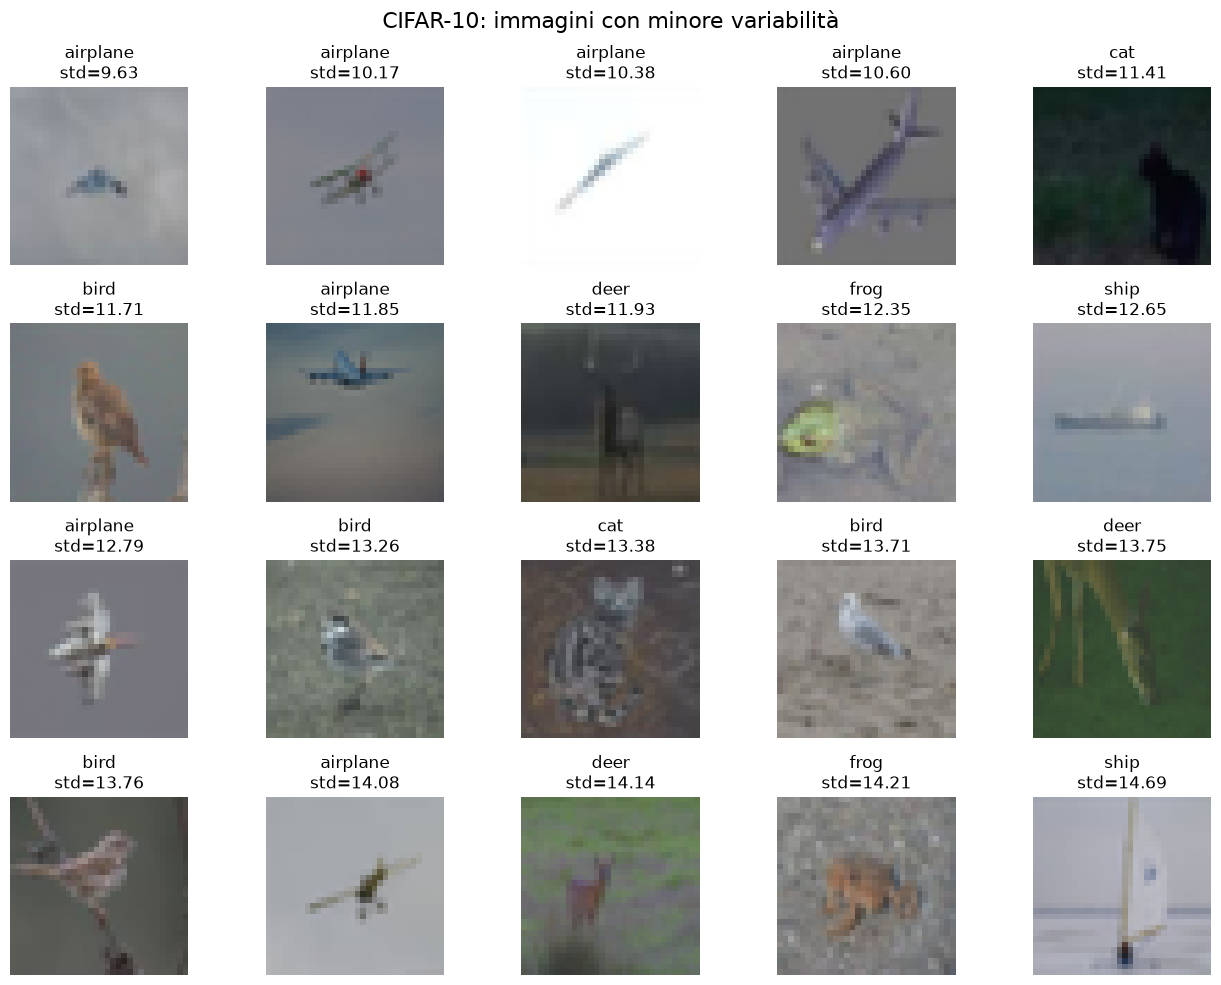

Figura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_low_variance_images.png


In [34]:
number_to_show = min(
    20,
    len(x_train_full)
)

lowest_variance_indices = np.argsort(
    image_std
)[:number_to_show]

fig, axes = plt.subplots(
    nrows=4,
    ncols=5,
    figsize=(13, 10)
)

axes = axes.ravel()

for axis, image_index in zip(
    axes,
    lowest_variance_indices
):
    label = y_train_full[image_index]

    axis.imshow(
        x_train_full[image_index]
    )

    axis.set_title(
        f"{CLASS_NAMES[label]}\n"
        f"std={image_std[image_index]:.2f}"
    )

    axis.axis("off")

plt.suptitle(
    "CIFAR-10: immagini con minore variabilità",
    fontsize=16
)

plt.tight_layout()

low_variance_path = (
    FIGURES_DIR / "cifar10_low_variance_images.png"
)

plt.savefig(
    low_variance_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figura salvata in:")
print(low_variance_path)

In [36]:
def compute_image_hashes(images):
    hashes = []

    for image in images:
        image_hash = hashlib.sha256(
            image.tobytes()
        ).hexdigest()

        hashes.append(image_hash)

    return np.array(hashes)


start_time = time.perf_counter()

train_hashes = compute_image_hashes(
    x_train_full
)

test_hashes = compute_image_hashes(
    x_test
)

hash_elapsed_time = (
    time.perf_counter()
    - start_time
)

print(
    "Tempo impiegato per gli hash:",
    f"{hash_elapsed_time:.2f} secondi"
)

Tempo impiegato per gli hash: 0.35 secondi


In [37]:
train_unique_hashes = np.unique(
    train_hashes
)

test_unique_hashes = np.unique(
    test_hashes
)

train_duplicate_count = (
    len(train_hashes)
    - len(train_unique_hashes)
)

test_duplicate_count = (
    len(test_hashes)
    - len(test_unique_hashes)
)

print(
    "Duplicati esatti nel training:",
    train_duplicate_count
)

print(
    "Duplicati esatti nel test:",
    test_duplicate_count
)

Duplicati esatti nel training: 0
Duplicati esatti nel test: 0


In [38]:
cross_split_hashes = np.intersect1d(
    train_unique_hashes,
    test_unique_hashes
)

cross_split_duplicate_count = len(
    cross_split_hashes
)

print(
    "Immagini esatte presenti sia nel training "
    "sia nel test:",
    cross_split_duplicate_count
)

Immagini esatte presenti sia nel training sia nel test: 0


In [40]:
def find_conflicting_duplicate_labels(
    hashes,
    labels
):
    hash_to_labels = {}

    for image_hash, label in zip(
        hashes,
        labels
    ):
        if image_hash not in hash_to_labels:
            hash_to_labels[image_hash] = set()

        hash_to_labels[image_hash].add(
            int(label)
        )

    conflicts = {
        image_hash: label_set
        for image_hash, label_set
        in hash_to_labels.items()
        if len(label_set) > 1
    }

    return conflicts


train_label_conflicts = (
    find_conflicting_duplicate_labels(
        train_hashes,
        y_train_full
    )
)

test_label_conflicts = (
    find_conflicting_duplicate_labels(
        test_hashes,
        y_test
    )
)

combined_hashes = np.concatenate([
    train_hashes,
    test_hashes
])

combined_labels = np.concatenate([
    y_train_full,
    y_test
])

global_label_conflicts = (
    find_conflicting_duplicate_labels(
        combined_hashes,
        combined_labels
    )
)

print(
    "Conflitti nel training:",
    len(train_label_conflicts)
)

print(
    "Conflitti nel test:",
    len(test_label_conflicts)
)

print(
    "Conflitti considerando insieme "
    "training e test:",
    len(global_label_conflicts)
)

Conflitti nel training: 0
Conflitti nel test: 0
Conflitti considerando insieme training e test: 0


In [42]:
duplicates_summary_df = pd.DataFrame({
    "control": [
        "Duplicati nel training",
        "Duplicati nel test",
        "Duplicati tra training e test",
        "Conflitti di etichetta nel training",
        "Conflitti di etichetta nel test",
        "Conflitti globali di etichetta"
    ],
    "count": [
        train_duplicate_count,
        test_duplicate_count,
        cross_split_duplicate_count,
        len(train_label_conflicts),
        len(test_label_conflicts),
        len(global_label_conflicts)
    ]
})

duplicates_summary_df


duplicates_summary_path = (
    METRICS_DIR / "cifar10_duplicates_summary.csv"
)

duplicates_summary_df.to_csv(
    duplicates_summary_path,
    index=False
)

print("Riepilogo salvato in:")
print(duplicates_summary_path)

Riepilogo salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_duplicates_summary.csv


In [43]:
number_of_classes = len(CLASS_NAMES)

theoretical_random_accuracy = ( 1.0 /number_of_classes)

print("accuracy teorica della baseline casuale:" f"{theoretical_random_accuracy:.2%}"
      )

accuracy teorica della baseline casuale:10.00%


In [44]:
baseline_rng = np.random.default_rng(
    SEED
)

random_predictions = baseline_rng.integers(
    low=0,
    high=number_of_classes,
    size=len(y_test)
)

random_baseline_accuracy = accuracy_score(
    y_test,
    random_predictions
)

print(
    "Accuracy osservata della baseline casuale:",
    f"{random_baseline_accuracy:.4f}"
)

print(
    "Percentuale:",
    f"{random_baseline_accuracy:.2%}"
)

Accuracy osservata della baseline casuale: 0.0989
Percentuale: 9.89%


In [45]:
majority_class = int(
    np.argmax(train_counts)
)

majority_predictions = np.full(
    shape=len(y_test),
    fill_value=majority_class
)

majority_baseline_accuracy = accuracy_score(
    y_test,
    majority_predictions
)

print(
    "Classe maggioritaria:",
    majority_class,
    CLASS_NAMES[majority_class]
)

print(
    "Accuracy della majority baseline:",
    f"{majority_baseline_accuracy:.4f}"
)

print(
    "Percentuale:",
    f"{majority_baseline_accuracy:.2%}"
)

Classe maggioritaria: 0 airplane
Accuracy della majority baseline: 0.1000
Percentuale: 10.00%


In [46]:
class_probabilities = (
    train_counts
    / train_counts.sum()
)

stratified_predictions = (
    baseline_rng.choice(
        np.arange(number_of_classes),
        size=len(y_test),
        replace=True,
        p=class_probabilities
    )
)

stratified_baseline_accuracy = (
    accuracy_score(
        y_test,
        stratified_predictions
    )
)

print(
    "Probabilità delle classi:",
    class_probabilities
)

print(
    "Accuracy della baseline stratificata:",
    f"{stratified_baseline_accuracy:.4f}"
)

Probabilità delle classi: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Accuracy della baseline stratificata: 0.1032


In [48]:
baselines_df = pd.DataFrame({
    "baseline": [
        "Casuale teorica",
        "Casuale simulata",
        "Stratificata simulata",
        "Classe maggioritaria"
    ],
    "accuracy": [
        theoretical_random_accuracy,
        random_baseline_accuracy,
        stratified_baseline_accuracy,
        majority_baseline_accuracy
    ]
})

baselines_df["accuracy_percentage"] = (
    baselines_df["accuracy"] * 100
)

baselines_df

baselines_path = (
    METRICS_DIR / "cifar10_baselines.csv"
)

baselines_df.to_csv(
    baselines_path,
    index=False
)

print("Baseline salvate in:")
print(baselines_path)

Baseline salvate in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_baselines.csv


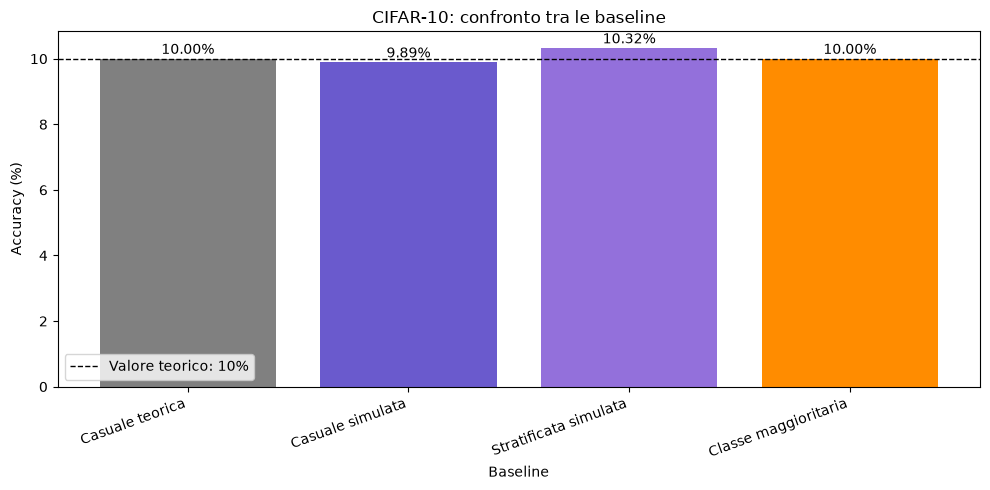

Grafico salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_baselines.png


In [49]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    baselines_df["baseline"],
    baselines_df["accuracy_percentage"],
    color=[
        "gray",
        "slateblue",
        "mediumpurple",
        "darkorange"
    ]
)

plt.axhline(
    y=10,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Valore teorico: 10%"
)

plt.title(
    "CIFAR-10: confronto tra le baseline"
)

plt.xlabel("Baseline")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20, ha="right")
plt.legend()

for bar, value in zip(
    bars,
    baselines_df["accuracy_percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

baselines_figure_path = (
    FIGURES_DIR / "cifar10_baselines.png"
)

plt.savefig(
    baselines_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafico salvato in:")
print(baselines_figure_path)

In [51]:
phase_1b_summary = {
    "dataset": "CIFAR-10",
    "seed": int(SEED),

    "training_images": int(
        len(x_train_full)
    ),

    "test_images": int(
        len(x_test)
    ),

    "image_shape": [
        int(value)
        for value in x_train_full.shape[1:]
    ],

    "number_of_classes": int(
        number_of_classes
    ),

    "balanced_training": bool(
        train_counts.min()
        == train_counts.max()
    ),

    "balanced_test": bool(
        test_counts.min()
        == test_counts.max()
    ),

    "training_examples_per_class": (
        train_counts.tolist()
    ),

    "test_examples_per_class": (
        test_counts.tolist()
    ),

    "pixel_minimum": int(
        x_train_full.min()
    ),

    "pixel_maximum": int(
        x_train_full.max()
    ),

    "rgb_means_normalized": (
        channel_means.tolist()
    ),

    "rgb_standard_deviations_normalized": (
        channel_stds.tolist()
    ),

    "constant_images": int(
        len(constant_image_indices)
    ),

    "low_variance_images": int(
        len(low_variance_indices)
    ),

    "low_variance_threshold": float(
        LOW_VARIANCE_THRESHOLD
    ),

    "training_duplicate_copies": int(
        train_duplicate_count
    ),

    "test_duplicate_copies": int(
        test_duplicate_count
    ),

    "cross_split_duplicates": int(
        cross_split_duplicate_count
    ),

    "global_label_conflicts": int(
        len(global_label_conflicts)
    ),

    "theoretical_random_accuracy": float(
        theoretical_random_accuracy
    ),

    "simulated_random_accuracy": float(
        random_baseline_accuracy
    ),

    "majority_baseline_accuracy": float(
        majority_baseline_accuracy
    )
}

phase_1b_summary_path = (
    METRICS_DIR / "cifar10_phase1b_summary.json"
)

with open(
    phase_1b_summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        phase_1b_summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Riepilogo JSON salvato in:")
print(phase_1b_summary_path)

Riepilogo JSON salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_phase1b_summary.json


fase 1 blocco C suddivisione dei training, validation e test


In [52]:
required_variables = {
    "x_train_full": x_train_full,
    "y_train_full": y_train_full,
    "x_test": x_test,
    "y_test": y_test,
    "CLASS_NAMES": CLASS_NAMES,
    "CLASS_NAMES_IT": CLASS_NAMES_IT,
    "SEED": SEED
}

for variable_name, variable_value in required_variables.items():
    print(
        f"{variable_name:<20} -> "
        f"{type(variable_value).__name__}"
    )

assert x_train_full.shape == (50000, 32, 32, 3)
assert y_train_full.shape == (50000,)

assert x_test.shape == (10000, 32, 32, 3)
assert y_test.shape == (10000,)

assert len(CLASS_NAMES) == 10
assert len(CLASS_NAMES_IT) == 10
assert SEED == 42

print("\nControlli iniziali superati.")

x_train_full         -> ndarray
y_train_full         -> ndarray
x_test               -> ndarray
y_test               -> ndarray
CLASS_NAMES          -> list
CLASS_NAMES_IT       -> list
SEED                 -> int

Controlli iniziali superati.


In [53]:
all_train_indices = np.arange(
    len(x_train_full)
)

print(
    "Numero totale di indici:",
    len(all_train_indices)
)

print(
    "Primo indice:",
    all_train_indices[0]
)

print(
    "Ultimo indice:",
    all_train_indices[-1]
)

Numero totale di indici: 50000
Primo indice: 0
Ultimo indice: 49999


In [54]:
idx_train, idx_val = train_test_split(
    all_train_indices,
    test_size=0.10,
    random_state=SEED,
    shuffle=True,
    stratify=y_train_full
)

print(
    "Numero indici training:",
    len(idx_train)
)

print(
    "Numero indici validation:",
    len(idx_val)
)

Numero indici training: 45000
Numero indici validation: 5000


In [55]:
idx_train = np.sort(idx_train)
idx_val = np.sort(idx_val)

print(
    "Primi 10 indici del training:"
)

print(idx_train[:10])

print(
    "\nPrimi 10 indici della validation:"
)

print(idx_val[:10])

Primi 10 indici del training:
[ 0  2  3  4  5  6  8  9 10 11]

Primi 10 indici della validation:
[  1   7  33  36  39  77  79  88  99 103]


In [56]:
x_train = x_train_full[idx_train]
y_train = y_train_full[idx_train]

x_val = x_train_full[idx_val]
y_val = y_train_full[idx_val]

print(
    "Forma x_train:",
    x_train.shape
)

print(
    "Forma y_train:",
    y_train.shape
)

print(
    "Forma x_val:",
    x_val.shape
)

print(
    "Forma y_val:",
    y_val.shape
)

print(
    "Forma x_test:",
    x_test.shape
)

print(
    "Forma y_test:",
    y_test.shape
)

Forma x_train: (45000, 32, 32, 3)
Forma y_train: (45000,)
Forma x_val: (5000, 32, 32, 3)
Forma y_val: (5000,)
Forma x_test: (10000, 32, 32, 3)
Forma y_test: (10000,)


In [57]:
assert x_train.shape == (45000, 32, 32, 3)
assert y_train.shape == (45000,)

assert x_val.shape == (5000, 32, 32, 3)
assert y_val.shape == (5000,)

assert x_test.shape == (10000, 32, 32, 3)
assert y_test.shape == (10000,)

assert x_train.dtype == np.uint8
assert x_val.dtype == np.uint8
assert x_test.dtype == np.uint8

print(
    "Forme e datatype degli split corretti."
)

Forme e datatype degli split corretti.


In [58]:
train_index_set = set(
    idx_train.tolist()
)

val_index_set = set(
    idx_val.tolist()
)

overlapping_indices = (
    train_index_set.intersection(
        val_index_set
    )
)

print(
    "Numero di indici condivisi:",
    len(overlapping_indices)
)

assert len(overlapping_indices) == 0

print(
    "Nessuna sovrapposizione tra "
    "training e validation."
)

Numero di indici condivisi: 0
Nessuna sovrapposizione tra training e validation.


In [59]:
combined_internal_indices = np.concatenate([
    idx_train,
    idx_val
])

unique_combined_indices = np.unique(
    combined_internal_indices
)

print(
    "Numero totale di indici combinati:",
    len(combined_internal_indices)
)

print(
    "Numero di indici unici:",
    len(unique_combined_indices)
)

assert len(combined_internal_indices) == 50000
assert len(unique_combined_indices) == 50000

assert np.array_equal(
    np.sort(unique_combined_indices),
    all_train_indices
)

print(
    "Training e validation coprono "
    "l'intero training ufficiale."
)

Numero totale di indici combinati: 50000
Numero di indici unici: 50000
Training e validation coprono l'intero training ufficiale.


In [60]:
internal_train_counts = np.bincount(
    y_train,
    minlength=len(CLASS_NAMES)
)

validation_counts = np.bincount(
    y_val,
    minlength=len(CLASS_NAMES)
)

official_test_counts = np.bincount(
    y_test,
    minlength=len(CLASS_NAMES)
)

print(
    "Distribuzione finale degli split:\n"
)

for class_id, class_name in enumerate(CLASS_NAMES):
    class_name_it = CLASS_NAMES_IT[class_id]

    train_count = internal_train_counts[class_id]
    val_count = validation_counts[class_id]
    test_count = official_test_counts[class_id]

    print(
        f"{class_id:2d} | "
        f"{class_name:<10} | "
        f"{class_name_it:<10} | "
        f"train={train_count:4d} | "
        f"val={val_count:3d} | "
        f"test={test_count:4d}"
    )

Distribuzione finale degli split:

 0 | airplane   | aeroplano  | train=4500 | val=500 | test=1000
 1 | automobile | automobile | train=4500 | val=500 | test=1000
 2 | bird       | uccello    | train=4500 | val=500 | test=1000
 3 | cat        | gatto      | train=4500 | val=500 | test=1000
 4 | deer       | cervo      | train=4500 | val=500 | test=1000
 5 | dog        | cane       | train=4500 | val=500 | test=1000
 6 | frog       | rana       | train=4500 | val=500 | test=1000
 7 | horse      | cavallo    | train=4500 | val=500 | test=1000
 8 | ship       | nave       | train=4500 | val=500 | test=1000
 9 | truck      | camion     | train=4500 | val=500 | test=1000


In [61]:
assert np.all(
    internal_train_counts == 4500
)

assert np.all(
    validation_counts == 500
)

assert np.all(
    official_test_counts == 1000
)

print(
    "Stratificazione verificata:"
)

print(
    "- 4.500 immagini per classe "
    "nel training"
)

print(
    "- 500 immagini per classe "
    "nella validation"
)

print(
    "- 1.000 immagini per classe "
    "nel test"
)

Stratificazione verificata:
- 4.500 immagini per classe nel training
- 500 immagini per classe nella validation
- 1.000 immagini per classe nel test


In [65]:
split_distribution_df = pd.DataFrame({
    "class_id": np.arange(
        len(CLASS_NAMES)
    ),
    "class_name": CLASS_NAMES,
    "class_name_it": CLASS_NAMES_IT,
    "training_count": internal_train_counts,
    "validation_count": validation_counts,
    "test_count": official_test_counts
})

split_distribution_df["total_count"] = (
    split_distribution_df["training_count"]
    + split_distribution_df["validation_count"]
    + split_distribution_df["test_count"]
)

split_distribution_df


split_distribution_df[
    "training_percentage"
] = (
    split_distribution_df["training_count"]
    / len(y_train)
    * 100
)

split_distribution_df[
    "validation_percentage"
] = (
    split_distribution_df["validation_count"]
    / len(y_val)
    * 100
)

split_distribution_df[
    "test_percentage"
] = (
    split_distribution_df["test_count"]
    / len(y_test)
    * 100
)

split_distribution_df

split_distribution_path = (
    METRICS_DIR
    / "cifar10_split_distribution.csv"
)

split_distribution_df.to_csv(
    split_distribution_path,
    index=False
)

print(
    "Distribuzione degli split salvata in:"
)

print(split_distribution_path)

Distribuzione degli split salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_split_distribution.csv


In [66]:
split_indices_path = (
    METRICS_DIR
    / "cifar10_split_indices_seed42.npz"
)

np.savez_compressed(
    split_indices_path,
    idx_train=idx_train,
    idx_val=idx_val,
    seed=np.array([SEED])
)

print(
    "Indici dello split salvati in:"
)

print(split_indices_path)

Indici dello split salvati in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_split_indices_seed42.npz


In [67]:
loaded_split = np.load(
    split_indices_path
)

loaded_idx_train = loaded_split[
    "idx_train"
]

loaded_idx_val = loaded_split[
    "idx_val"
]

loaded_seed = int(
    loaded_split["seed"][0]
)

print(
    "Training caricato:",
    loaded_idx_train.shape
)

print(
    "Validation caricata:",
    loaded_idx_val.shape
)

print(
    "Seed caricato:",
    loaded_seed
)

assert np.array_equal(
    loaded_idx_train,
    idx_train
)

assert np.array_equal(
    loaded_idx_val,
    idx_val
)

assert loaded_seed == SEED

print(
    "File degli indici verificato correttamente."
)

Training caricato: (45000,)
Validation caricata: (5000,)
Seed caricato: 42
File degli indici verificato correttamente.


In [70]:
def rebuild_internal_splits(
    x_train_full,
    y_train_full,
    split_file_path
):
    split_data = np.load(
        split_file_path
    )

    saved_idx_train = split_data[
        "idx_train"
    ]

    saved_idx_val = split_data[
        "idx_val"
    ]

    rebuilt_x_train = x_train_full[
        saved_idx_train
    ]

    rebuilt_y_train = y_train_full[
        saved_idx_train
    ]

    rebuilt_x_val = x_train_full[
        saved_idx_val
    ]

    rebuilt_y_val = y_train_full[
        saved_idx_val
    ]

    return (
        rebuilt_x_train,
        rebuilt_y_train,
        rebuilt_x_val,
        rebuilt_y_val
    )

(
    x_train_check,
    y_train_check,
    x_val_check,
    y_val_check
) = rebuild_internal_splits(
    x_train_full,
    y_train_full,
    split_indices_path
)

assert np.array_equal(
    x_train_check,
    x_train
)

assert np.array_equal(
    y_train_check,
    y_train
)

assert np.array_equal(
    x_val_check,
    x_val
)

assert np.array_equal(
    y_val_check,
    y_val
)

print(
    "Ricostruzione degli split riuscita."
)

Ricostruzione degli split riuscita.


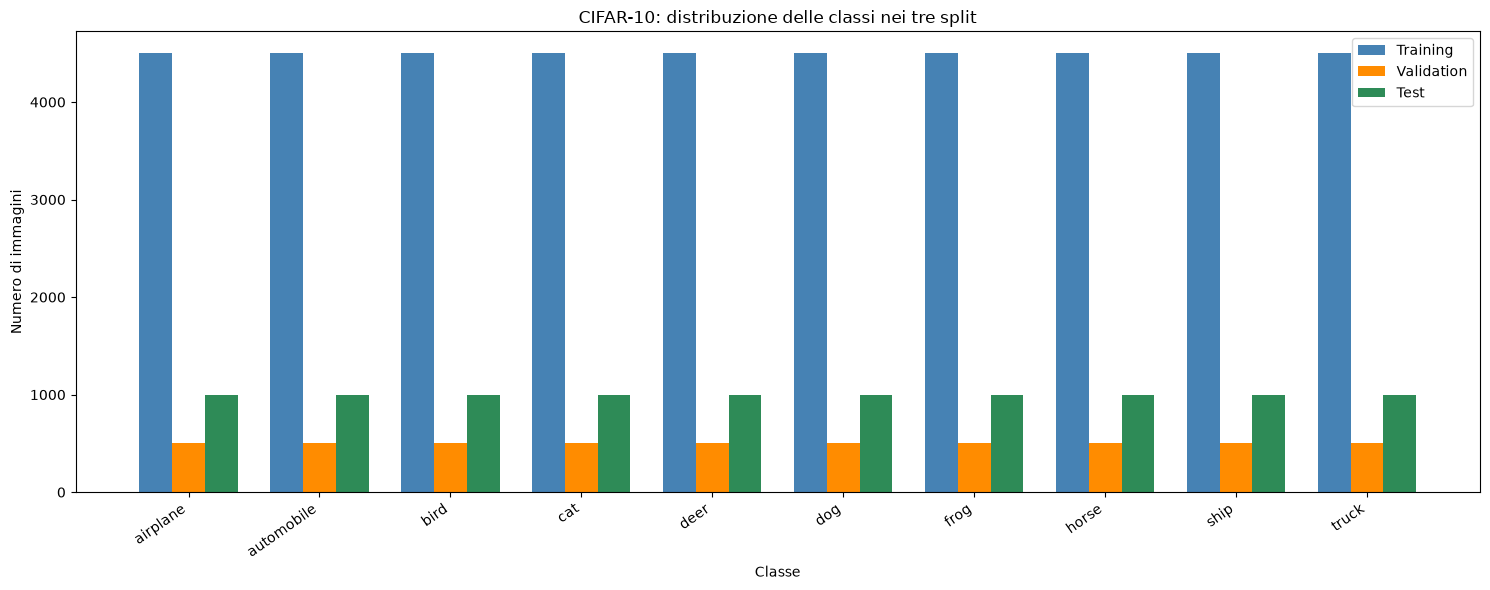

Grafico degli split salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_split_distribution.png


In [71]:
class_positions = np.arange(
    len(CLASS_NAMES)
)

bar_width = 0.25

plt.figure(figsize=(15, 6))

plt.bar(
    class_positions - bar_width,
    internal_train_counts,
    width=bar_width,
    label="Training",
    color="steelblue"
)

plt.bar(
    class_positions,
    validation_counts,
    width=bar_width,
    label="Validation",
    color="darkorange"
)

plt.bar(
    class_positions + bar_width,
    official_test_counts,
    width=bar_width,
    label="Test",
    color="seagreen"
)

plt.title(
    "CIFAR-10: distribuzione delle classi "
    "nei tre split"
)

plt.xlabel("Classe")
plt.ylabel("Numero di immagini")

plt.xticks(
    class_positions,
    CLASS_NAMES,
    rotation=35,
    ha="right"
)

plt.legend()
plt.tight_layout()

split_figure_path = (
    FIGURES_DIR
    / "cifar10_split_distribution.png"
)

plt.savefig(
    split_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Grafico degli split salvato in:"
)

print(split_figure_path)

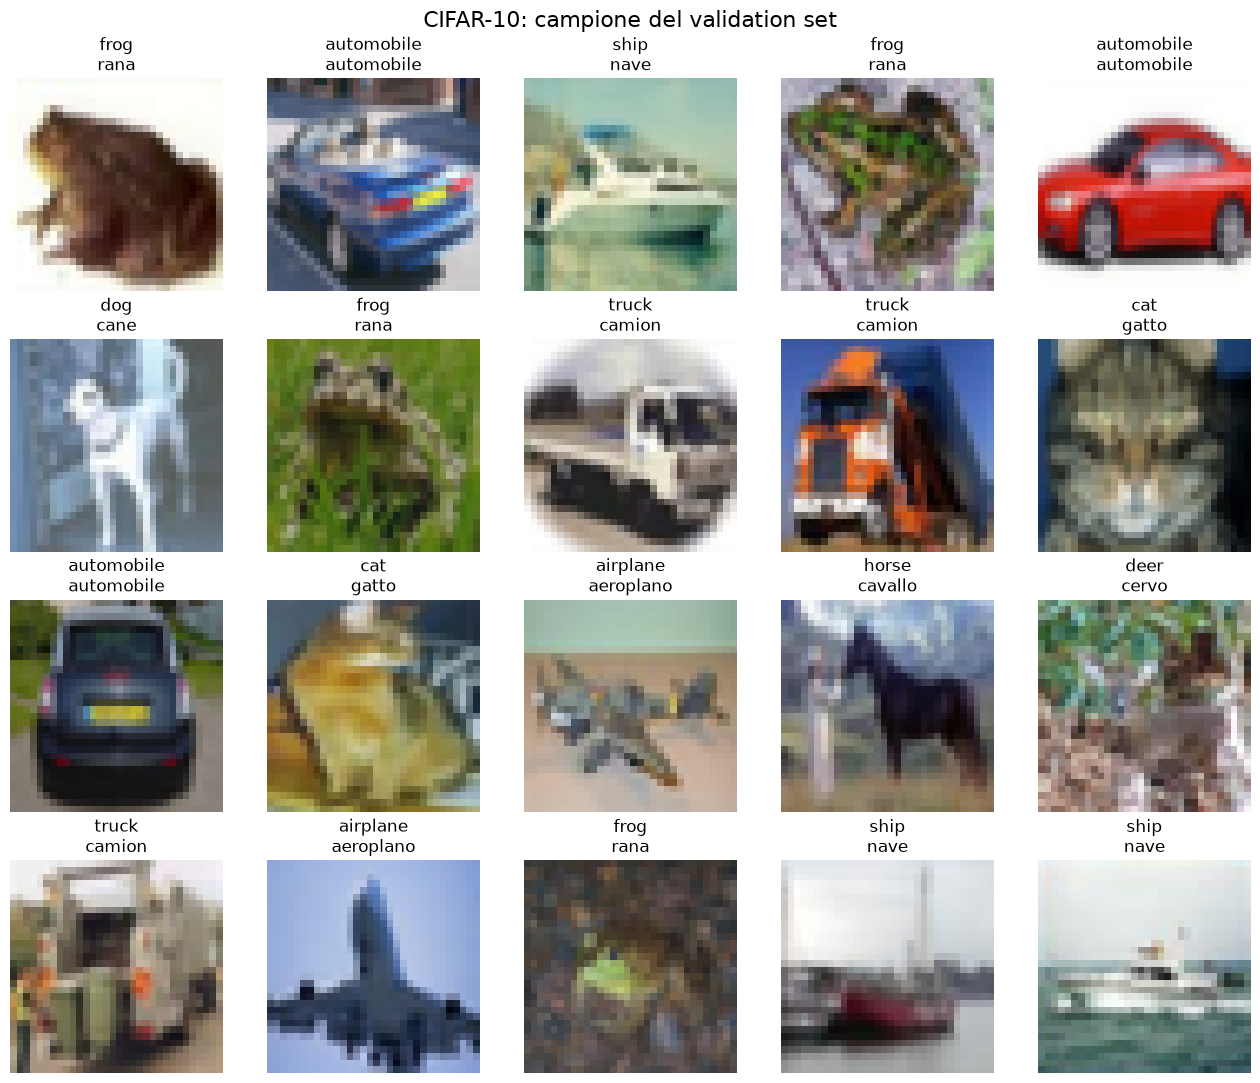

Campione della validation salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_validation_sample.png


In [72]:
validation_rng = np.random.default_rng(
    SEED
)

validation_sample_indices = (
    validation_rng.choice(
        len(x_val),
        size=20,
        replace=False
    )
)

fig, axes = plt.subplots(
    nrows=4,
    ncols=5,
    figsize=(13, 11)
)

axes = axes.ravel()

for axis, local_index in zip(
    axes,
    validation_sample_indices
):
    label = int(
        y_val[local_index]
    )

    axis.imshow(
        x_val[local_index]
    )

    axis.set_title(
        f"{CLASS_NAMES[label]}\n"
        f"{CLASS_NAMES_IT[label]}"
    )

    axis.axis("off")

plt.suptitle(
    "CIFAR-10: campione del validation set",
    fontsize=16
)

plt.tight_layout()

validation_sample_path = (
    FIGURES_DIR
    / "cifar10_validation_sample.png"
)

plt.savefig(
    validation_sample_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Campione della validation salvato in:"
)

print(validation_sample_path)

In [73]:
assert len(x_test) == 10000
assert len(y_test) == 10000

assert x_test.shape == (
    10000,
    32,
    32,
    3
)

assert y_test.shape == (10000,)

assert x_test.dtype == np.uint8

assert x_test.min() == 0
assert x_test.max() == 255

assert np.all(
    np.bincount(
        y_test,
        minlength=10
    ) == 1000
)

print(
    "Test ufficiale intatto e verificato."
)


Test ufficiale intatto e verificato.


In [75]:
def hash_numpy_array(array):
    return hashlib.sha256(
        array.tobytes()
    ).hexdigest()

train_indices_hash = hash_numpy_array(
    idx_train
)

validation_indices_hash = hash_numpy_array(
    idx_val
)

print(
    "Hash indici training:"
)

print(train_indices_hash)

print(
    "\nHash indici validation:"
)

print(validation_indices_hash)


Hash indici training:
b99301bfd9655f1c490146bd48208bad11da518bafdd011d750ced3414b95dcb

Hash indici validation:
280540fcdfde8a413eee40aec0bc950f1fde09954d77df5546a1e4138057becf


In [78]:
phase_1c_summary = {
    "dataset": "CIFAR-10",
    "seed": int(SEED),

    "official_training_size": int(
        len(x_train_full)
    ),

    "internal_training_size": int(
        len(x_train)
    ),

    "validation_size": int(
        len(x_val)
    ),

    "official_test_size": int(
        len(x_test)
    ),

    "internal_training_percentage": 90.0,
    "validation_percentage": 10.0,

    "stratified_split": True,
    "training_validation_overlap": int(
        len(overlapping_indices)
    ),

    "training_examples_per_class": (
        internal_train_counts.tolist()
    ),

    "validation_examples_per_class": (
        validation_counts.tolist()
    ),

    "test_examples_per_class": (
        official_test_counts.tolist()
    ),

    "training_indices_hash": (
        train_indices_hash
    ),

    "validation_indices_hash": (
        validation_indices_hash
    ),

    "test_used_for_tuning": False
}

phase_1c_summary_path = (
    METRICS_DIR
    / "cifar10_phase1c_summary.json"
)

with open(
    phase_1c_summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        phase_1c_summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    "Riepilogo del Blocco C salvato in:"
)

print(phase_1c_summary_path)


Riepilogo del Blocco C salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_phase1c_summary.json


In [79]:
splits_summary_df = pd.DataFrame({
    "split": [
        "Training",
        "Validation",
        "Test"
    ],
    "number_of_images": [
        len(x_train),
        len(x_val),
        len(x_test)
    ],
    "percentage_of_total_dataset": [
        len(x_train) / 60000 * 100,
        len(x_val) / 60000 * 100,
        len(x_test) / 60000 * 100
    ],
    "purpose": [
        "Aggiornamento dei pesi",
        "Scelta degli iperparametri",
        "Valutazione finale"
    ]
})

splits_summary_df

,split,number_of_images,percentage_of_total_dataset,purpose
0,Training,45000,75.000000,Aggiornamento dei pesi
1,Validation,5000,8.333333,Scelta degli iperparametri
2,Test,10000,16.666667,Valutazione finale


In [80]:
phase_1c_checks = {
    "training_size_correct": (
        len(x_train) == 45000
    ),

    "validation_size_correct": (
        len(x_val) == 5000
    ),

    "test_size_correct": (
        len(x_test) == 10000
    ),

    "training_balanced": bool(
        np.all(
            internal_train_counts == 4500
        )
    ),

    "validation_balanced": bool(
        np.all(
            validation_counts == 500
        )
    ),

    "test_balanced": bool(
        np.all(
            official_test_counts == 1000
        )
    ),

    "no_train_validation_overlap": (
        len(overlapping_indices) == 0
    ),

    "complete_training_coverage": (
        len(unique_combined_indices) == 50000
    ),

    "split_file_exists": (
        split_indices_path.exists()
    ),

    "test_remains_uint8": (
        x_test.dtype == np.uint8
    )
}

for check_name, check_result in (
    phase_1c_checks.items()
):
    status = (
        "SUPERATO"
        if check_result
        else "NON SUPERATO"
    )

    print(
        f"{check_name:<35} -> {status}"
    )

assert all(
    phase_1c_checks.values()
)

print(
    "\nBLOCCO C COMPLETATO CORRETTAMENTE."
)

training_size_correct               -> SUPERATO
validation_size_correct             -> SUPERATO
test_size_correct                   -> SUPERATO
training_balanced                   -> SUPERATO
validation_balanced                 -> SUPERATO
test_balanced                       -> SUPERATO
no_train_validation_overlap         -> SUPERATO
complete_training_coverage          -> SUPERATO
split_file_exists                   -> SUPERATO
test_remains_uint8                  -> SUPERATO

BLOCCO C COMPLETATO CORRETTAMENTE.


## Suddivisione del dataset

Il test set ufficiale di CIFAR-10, composto da 10.000 immagini, è stato
mantenuto intatto e riservato alla valutazione finale.

Le 50.000 immagini del training ufficiale sono state suddivise in
45.000 immagini di training interno e 5.000 immagini di validation.
La suddivisione è stata effettuata mediante uno split stratificato
90%-10%, utilizzando il seed 42.

La stratificazione ha mantenuto invariata la distribuzione delle
classi. Il training interno contiene 4.500 immagini per ogni classe,
la validation ne contiene 500 per classe e il test ufficiale ne
contiene 1.000 per classe.

È stata verificata l'assenza di sovrapposizioni tra gli indici di
training e validation. L'unione dei due insiemi copre tutte le 50.000
immagini del training ufficiale, senza perdite o duplicazioni degli
indici.

Gli indici della suddivisione sono stati salvati in formato NPZ per
garantire la riproducibilità e assicurare che MLP e CNN siano
addestrate e validate sugli stessi esempi.

# Fase 2: preprocessing e pipeline TensorFlow

In questa fase le immagini vengono preparate per l'addestramento
della MLP e della CNN.

Le operazioni previste sono:

- conversione da uint8 a float32;
- normalizzazione dei pixel nell'intervallo [0, 1];
- costruzione delle pipeline tf.data;
- mescolamento del solo training set;
- suddivisione in mini-batch;
- prefetching;
- verifica di forme, etichette e intervalli numerici.

Training, validation e test utilizzano la stessa normalizzazione.
Solo il training viene mescolato ed eventualmente sottoposto a
data augmentation.

In [81]:
print("Training:")
print("  x_train:", x_train.shape, x_train.dtype)
print("  y_train:", y_train.shape, y_train.dtype)

print("\nValidation:")
print("  x_val:", x_val.shape, x_val.dtype)
print("  y_val:", y_val.shape, y_val.dtype)

print("\nTest:")
print("  x_test:", x_test.shape, x_test.dtype)
print("  y_test:", y_test.shape, y_test.dtype)

Training:
  x_train: (45000, 32, 32, 3) uint8
  y_train: (45000,) uint8

Validation:
  x_val: (5000, 32, 32, 3) uint8
  y_val: (5000,) uint8

Test:
  x_test: (10000, 32, 32, 3) uint8
  y_test: (10000,) uint8


In [82]:
assert x_train.shape == (45000, 32, 32, 3)
assert x_val.shape == (5000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)

assert y_train.shape == (45000,)
assert y_val.shape == (5000,)
assert y_test.shape == (10000,)

assert x_train.dtype == np.uint8
assert x_val.dtype == np.uint8
assert x_test.dtype == np.uint8

assert x_train.min() >= 0
assert x_train.max() <= 255

assert x_val.min() >= 0
assert x_val.max() <= 255

assert x_test.min() >= 0
assert x_test.max() <= 255

print("Controlli iniziali della Fase 2 superati.")

Controlli iniziali della Fase 2 superati.


In [83]:
import math 

BATCH_SIZE = 64

training_steps_per_epoch = math.ceil(len(x_train) / BATCH_SIZE)
validation_steps = math.ceil(len(x_val) / BATCH_SIZE)
test_steps = math.ceil(len(x_test) /BATCH_SIZE)

print("Batch size: ", BATCH_SIZE)
print("batch di training per epoca.:", training_steps_per_epoch)
print("batch di validation: ", validation_steps)
print("Batch di test:", test_steps)


Batch size:  64
batch di training per epoca.: 704
batch di validation:  79
Batch di test: 157


In [88]:
def preprocess_image(image, label):
    image = tf.cast(
        image,
        tf.float32
    )

    image = image / 255.0

    label = tf.cast(
        label,
        tf.int64
    )

    return image, label

sample_image = x_train[0]
sample_label = y_train[0]

processed_image, processed_label = (
    preprocess_image(
        sample_image,
        sample_label
    )
)

print("Immagine originale:")
print("  dtype:", sample_image.dtype)
print("  minimo:", sample_image.min())
print("  massimo:", sample_image.max())
print("  forma:", sample_image.shape)

print("\nImmagine normalizzata:")
print("  dtype:", processed_image.dtype)
print("  minimo:", float(tf.reduce_min(processed_image)))
print("  massimo:", float(tf.reduce_max(processed_image)))
print("  forma:", processed_image.shape)

print("\nEtichetta originale:", sample_label)
print("Etichetta convertita:", processed_label.numpy())
print("Tipo etichetta:", processed_label.dtype)

assert processed_image.shape == (32, 32, 3)
assert processed_image.dtype == tf.float32
assert processed_label.dtype == tf.int64

assert float(tf.reduce_min(processed_image)) >= 0.0
assert float(tf.reduce_max(processed_image)) <= 1.0

assert int(processed_label.numpy()) == int(sample_label)

print("Funzione di preprocessing verificata.")

Immagine originale:
  dtype: uint8
  minimo: 0
  massimo: 255
  forma: (32, 32, 3)

Immagine normalizzata:
  dtype: <dtype: 'float32'>
  minimo: 0.0
  massimo: 1.0
  forma: (32, 32, 3)

Etichetta originale: 6
Etichetta convertita: 6
Tipo etichetta: <dtype: 'int64'>
Funzione di preprocessing verificata.


In [90]:
train_ds_raw = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

val_ds_raw = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

test_ds_raw = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

print("Dataset TensorFlow grezzi creati.")

print("Training raw:")
print(train_ds_raw.element_spec)

print("\nValidation raw:")
print(val_ds_raw.element_spec)

print("\nTest raw:")
print(test_ds_raw.element_spec)


Dataset TensorFlow grezzi creati.
Training raw:
(TensorSpec(shape=(32, 32, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.uint8, name=None))

Validation raw:
(TensorSpec(shape=(32, 32, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.uint8, name=None))

Test raw:
(TensorSpec(shape=(32, 32, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.uint8, name=None))


In [91]:
AUTOTUNE = tf.data.AUTOTUNE

SHUFFLE_BUFFER_SIZE = len(x_train)

print("AUTOTUNE:", AUTOTUNE)
print("Shuffle buffer:", SHUFFLE_BUFFER_SIZE)

AUTOTUNE: -1
Shuffle buffer: 45000


In [94]:
train_ds = train_ds_raw.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.cache()

train_ds = train_ds.shuffle(
    buffer_size=SHUFFLE_BUFFER_SIZE,
    seed=SEED,
    reshuffle_each_iteration=True
)

train_ds = train_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

train_ds = train_ds.prefetch(
    AUTOTUNE
)

print("Pipeline di training creata.")

Pipeline di training creata.


In [95]:
val_ds = val_ds_raw.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.cache()

val_ds = val_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

print("Pipeline di validation creata.")

Pipeline di validation creata.


In [96]:
test_ds = test_ds_raw.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.cache()

test_ds = test_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

print("Pipeline di test creata.")

Pipeline di test creata.


In [97]:
for batch_images, batch_labels in train_ds.take(1):
    print("Forma immagini:", batch_images.shape)
    print("Forma etichette:", batch_labels.shape)

    print("Tipo immagini:", batch_images.dtype)
    print("Tipo etichette:", batch_labels.dtype)

    print(
        "Pixel minimo:",
        float(tf.reduce_min(batch_images))
    )

    print(
        "Pixel massimo:",
        float(tf.reduce_max(batch_images))
    )

    print(
        "Prime 10 etichette:",
        batch_labels[:10].numpy()
    )

Forma immagini: (64, 32, 32, 3)
Forma etichette: (64,)
Tipo immagini: <dtype: 'float32'>
Tipo etichette: <dtype: 'int64'>
Pixel minimo: 0.0
Pixel massimo: 1.0
Prime 10 etichette: [7 4 3 8 8 4 1 0 8 5]


In [98]:
for batch_images, batch_labels in train_ds.take(1):
    assert batch_images.shape == (
        BATCH_SIZE,
        32,
        32,
        3
    )

    assert batch_labels.shape == (
        BATCH_SIZE,
    )

    assert batch_images.dtype == tf.float32
    assert batch_labels.dtype == tf.int64

    assert float(
        tf.reduce_min(batch_images)
    ) >= 0.0

    assert float(
        tf.reduce_max(batch_images)
    ) <= 1.0

    assert int(
        tf.reduce_min(batch_labels)
    ) >= 0

    assert int(
        tf.reduce_max(batch_labels)
    ) <= 9

print("Primo batch di training verificato.")

Primo batch di training verificato.


In [99]:
for name, dataset in [
    ("validation", val_ds),
    ("test", test_ds)
]:
    for batch_images, batch_labels in dataset.take(1):
        print(f"\nDataset: {name}")
        print("Immagini:", batch_images.shape)
        print("Etichette:", batch_labels.shape)
        print("Dtype immagini:", batch_images.dtype)
        print("Dtype etichette:", batch_labels.dtype)

        assert batch_images.shape[1:] == (
            32,
            32,
            3
        )

        assert batch_images.dtype == tf.float32
        assert batch_labels.dtype == tf.int64

        assert float(
            tf.reduce_min(batch_images)
        ) >= 0.0

        assert float(
            tf.reduce_max(batch_images)
        ) <= 1.0

print("\nValidation e test verificati.")


Dataset: validation
Immagini: (64, 32, 32, 3)
Etichette: (64,)
Dtype immagini: <dtype: 'float32'>
Dtype etichette: <dtype: 'int64'>

Dataset: test
Immagini: (64, 32, 32, 3)
Etichette: (64,)
Dtype immagini: <dtype: 'float32'>
Dtype etichette: <dtype: 'int64'>

Validation e test verificati.


In [101]:
train_cardinality = int(
    tf.data.experimental.cardinality(
        train_ds
    ).numpy()
)

val_cardinality = int(
    tf.data.experimental.cardinality(
        val_ds
    ).numpy()
)

test_cardinality = int(
    tf.data.experimental.cardinality(
        test_ds
    ).numpy()
)

print("Batch training:", train_cardinality)
print("Batch validation:", val_cardinality)
print("Batch test:", test_cardinality)

assert train_cardinality == training_steps_per_epoch
assert val_cardinality == validation_steps
assert test_cardinality == test_steps

print("Cardinalità delle pipeline corretta.")

Batch training: 704
Batch validation: 79
Batch test: 157
Cardinalità delle pipeline corretta.


In [104]:
def count_dataset_examples(dataset):
    total = 0

    for _, labels in dataset:
        total += int(
            tf.shape(labels)[0]
        )

    return total

train_example_count = count_dataset_examples(
    train_ds
)

val_example_count = count_dataset_examples(
    val_ds
)

test_example_count = count_dataset_examples(
    test_ds
)

print("Esempi training:", train_example_count)
print("Esempi validation:", val_example_count)
print("Esempi test:", test_example_count)

assert train_example_count == 45000
assert val_example_count == 5000
assert test_example_count == 10000

print("Tutti gli esempi sono presenti nelle pipeline.")

Esempi training: 45000
Esempi validation: 5000
Esempi test: 10000
Tutti gli esempi sono presenti nelle pipeline.


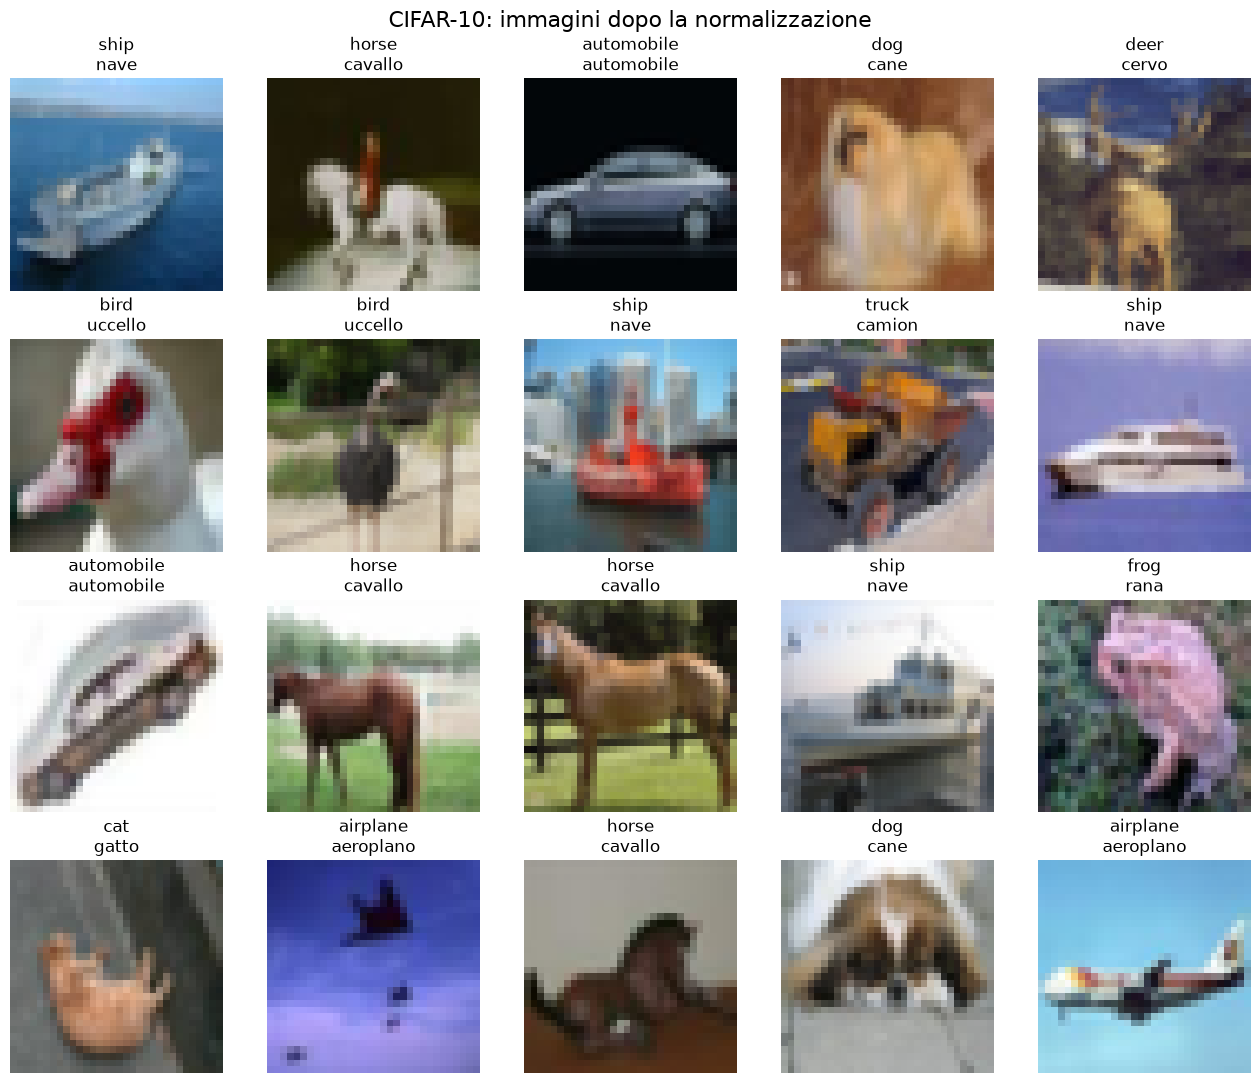

Figura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_normalized_training_sample.png


In [105]:
for batch_images, batch_labels in train_ds.take(1):
    images_to_show = batch_images[:20]
    labels_to_show = batch_labels[:20]

fig, axes = plt.subplots(
    nrows=4,
    ncols=5,
    figsize=(13, 11)
)

axes = axes.ravel()

for index, axis in enumerate(axes):
    image = images_to_show[index].numpy()
    label = int(labels_to_show[index].numpy())

    axis.imshow(image)

    axis.set_title(
        f"{CLASS_NAMES[label]}\n"
        f"{CLASS_NAMES_IT[label]}"
    )

    axis.axis("off")

plt.suptitle(
    "CIFAR-10: immagini dopo la normalizzazione",
    fontsize=16
)

plt.tight_layout()

normalized_sample_path = (
    FIGURES_DIR
    / "cifar10_normalized_training_sample.png"
)

plt.savefig(
    normalized_sample_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figura salvata in:")
print(normalized_sample_path)

In [106]:
first_iteration_labels = []

for _, labels in train_ds.take(1):
    first_iteration_labels = (
        labels.numpy().copy()
    )

second_iteration_labels = []

for _, labels in train_ds.take(1):
    second_iteration_labels = (
        labels.numpy().copy()
    )

print("Prime etichette, iterazione 1:")
print(first_iteration_labels[:15])

print("\nPrime etichette, iterazione 2:")
print(second_iteration_labels[:15])

same_order = np.array_equal(
    first_iteration_labels,
    second_iteration_labels
)

print("\nStesso ordine:", same_order)

Prime etichette, iterazione 1:
[9 8 6 9 2 9 3 8 2 0 8 3 8 6 2]

Prime etichette, iterazione 2:
[2 7 3 9 4 8 6 3 8 8 3 2 6 4 6]

Stesso ordine: False


In [108]:
pipeline_train_labels = []

for _, labels in train_ds:
    pipeline_train_labels.append(
        labels.numpy()
    )

pipeline_train_labels = np.concatenate(
    pipeline_train_labels
)

pipeline_train_counts = np.bincount(
    pipeline_train_labels,
    minlength=10
)

print("Distribuzione nella pipeline di training:")
print(pipeline_train_counts)

assert len(pipeline_train_labels) == 45000

assert np.all(
    pipeline_train_counts == 4500
)

print(
    "La pipeline mantiene il bilanciamento "
    "del training set."
)

Distribuzione nella pipeline di training:
[4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]
La pipeline mantiene il bilanciamento del training set.


In [109]:
dataset_options = tf.data.Options()

dataset_options.experimental_deterministic = True

train_ds = train_ds.with_options(
    dataset_options
)

val_ds = val_ds.with_options(
    dataset_options
)

test_ds = test_ds.with_options(
    dataset_options
)

print(
    "Opzione di determinismo applicata "
    "alle pipeline."
)

Opzione di determinismo applicata alle pipeline.


In [111]:
phase_2_config = {
    "framework": "TensorFlow",
    "api": "tf.keras",
    "seed": int(SEED),

    "image_shape": [
        32,
        32,
        3
    ],

    "number_of_classes": 10,

    "input_dtype_original": str(
        x_train.dtype
    ),

    "pipeline_image_dtype": "float32",
    "pipeline_label_dtype": "int64",

    "normalization": "divide_by_255",
    "normalized_minimum": 0.0,
    "normalized_maximum": 1.0,

    "batch_size": int(
        BATCH_SIZE
    ),

    "shuffle_buffer_size": int(
        SHUFFLE_BUFFER_SIZE
    ),

    "reshuffle_each_iteration": True,

    "training_size": int(
        len(x_train)
    ),

    "validation_size": int(
        len(x_val)
    ),

    "test_size": int(
        len(x_test)
    ),

    "training_batches": int(
        train_cardinality
    ),

    "validation_batches": int(
        val_cardinality
    ),

    "test_batches": int(
        test_cardinality
    ),

    "cache_enabled": True,
    "prefetch": "AUTOTUNE",

    "augmentation_enabled": False,

    "test_used_for_tuning": False
}

phase_2_config_path = (
    METRICS_DIR
    / "cifar10_phase2_pipeline_config.json"
)

with open(
    phase_2_config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        phase_2_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Configurazione salvata in:")
print(phase_2_config_path)

Configurazione salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_phase2_pipeline_config.json


In [112]:
pipeline_summary_df = pd.DataFrame({
    "dataset": [
        "Training",
        "Validation",
        "Test"
    ],

    "number_of_examples": [
        len(x_train),
        len(x_val),
        len(x_test)
    ],

    "number_of_batches": [
        train_cardinality,
        val_cardinality,
        test_cardinality
    ],

    "batch_size": [
        BATCH_SIZE,
        BATCH_SIZE,
        BATCH_SIZE
    ],

    "normalized": [
        True,
        True,
        True
    ],

    "shuffle": [
        True,
        False,
        False
    ],

    "augmentation": [
        False,
        False,
        False
    ],

    "purpose": [
        "Aggiornamento dei pesi",
        "Scelta degli iperparametri",
        "Valutazione finale"
    ]
})

pipeline_summary_df

pipeline_summary_path = (
    METRICS_DIR
    / "cifar10_pipeline_summary.csv"
)

pipeline_summary_df.to_csv(
    pipeline_summary_path,
    index=False
)

print("Tabella salvata in:")
print(pipeline_summary_path)

Tabella salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_pipeline_summary.csv


In [113]:
phase_2_checks = {
    "training_pipeline_exists": (
        train_ds is not None
    ),

    "validation_pipeline_exists": (
        val_ds is not None
    ),

    "test_pipeline_exists": (
        test_ds is not None
    ),

    "training_examples_correct": (
        train_example_count == 45000
    ),

    "validation_examples_correct": (
        val_example_count == 5000
    ),

    "test_examples_correct": (
        test_example_count == 10000
    ),

    "batch_size_correct": (
        BATCH_SIZE == 64
    ),

    "training_batches_correct": (
        train_cardinality == 704
    ),

    "validation_batches_correct": (
        val_cardinality == 79
    ),

    "test_batches_correct": (
        test_cardinality == 157
    ),

    "training_still_balanced": bool(
        np.all(
            pipeline_train_counts == 4500
        )
    ),

    "configuration_saved": (
        phase_2_config_path.exists()
    ),

    "summary_saved": (
        pipeline_summary_path.exists()
    )
}

for check_name, check_result in phase_2_checks.items():
    status = (
        "SUPERATO"
        if check_result
        else "NON SUPERATO"
    )

    print(
        f"{check_name:<35} -> {status}"
    )

assert all(
    phase_2_checks.values()
)

print(
    "\nFASE 2, BLOCCHI A E B, "
    "COMPLETATI CORRETTAMENTE."
)

training_pipeline_exists            -> SUPERATO
validation_pipeline_exists          -> SUPERATO
test_pipeline_exists                -> SUPERATO
training_examples_correct           -> SUPERATO
validation_examples_correct         -> SUPERATO
test_examples_correct               -> SUPERATO
batch_size_correct                  -> SUPERATO
training_batches_correct            -> SUPERATO
validation_batches_correct          -> SUPERATO
test_batches_correct                -> SUPERATO
training_still_balanced             -> SUPERATO
configuration_saved                 -> SUPERATO
summary_saved                       -> SUPERATO

FASE 2, BLOCCHI A E B, COMPLETATI CORRETTAMENTE.


## Preprocessing e pipeline TensorFlow

Le immagini dei tre split sono state convertite dal formato uint8 al
formato float32 e normalizzate dividendo ogni valore per 255. I pixel
sono stati quindi trasformati dall'intervallo originale [0, 255]
all'intervallo [0, 1].

Le etichette sono state mantenute come valori interi compresi tra 0 e
9, in modo da utilizzare la funzione di perdita
sparse categorical cross-entropy.

Le pipeline sono state costruite mediante l'API tf.data di TensorFlow.
Il training set viene normalizzato, salvato in cache, mescolato a ogni
epoca, suddiviso in mini-batch da 64 esempi e sottoposto a prefetching.

Validation e test utilizzano la stessa normalizzazione e lo stesso batch
size, ma non vengono mescolati e non ricevono data augmentation.

La pipeline di training contiene 704 batch, quella di validation 79
batch e quella di test 157 batch. È stato verificato che tutte le
45.000 immagini di training, le 5.000 immagini di validation e le
10.000 immagini di test siano presenti nelle rispettive pipeline.

# Fase 2, Blocco C: data augmentation

La data augmentation produce variazioni casuali delle immagini di
training senza modificarne la classe semantica.

Nel progetto verranno utilizzate trasformazioni moderate:

- riflessione orizzontale;
- piccole traslazioni orizzontali e verticali;
- piccole rotazioni.

L'augmentation sarà applicata esclusivamente durante il training della
CNN migliorata. Validation e test non saranno modificati.

La CNN base verrà inizialmente addestrata senza augmentation, in modo
da misurare separatamente il contributo di questa tecnica.

In [115]:
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal",
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.10,
            width_factor=0.10,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.05,
            fill_mode="reflect",
            seed=SEED
        )
    ],
    name="data_augmentation"
)
data_augmentation.summary()
print("Pipeline di data augmentation creata.")

Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Pipeline di data augmentation creata.


In [116]:
sample_image = tf.cast(
    x_train[0],
    tf.float32
) / 255.0

sample_label = int(y_train[0])

print("Forma:", sample_image.shape)
print("Classe:", CLASS_NAMES[sample_label])
print("Minimo:", float(tf.reduce_min(sample_image)))
print("Massimo:", float(tf.reduce_max(sample_image)))

Forma: (32, 32, 3)
Classe: frog
Minimo: 0.0
Massimo: 1.0


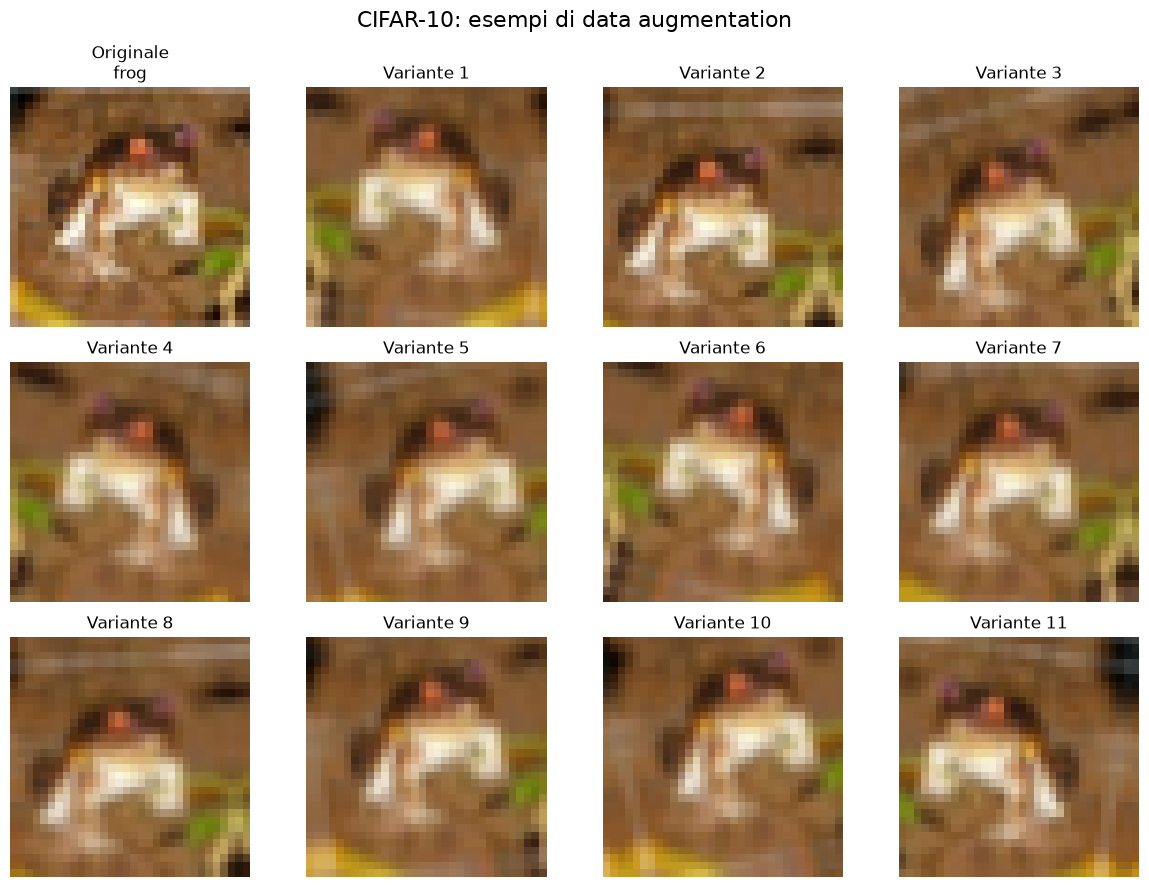

Figura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\cifar10_data_augmentation_examples.png


In [117]:
sample_image_batch = tf.expand_dims(
    sample_image,
    axis=0
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(12, 9)
)

axes = axes.ravel()

axes[0].imshow(sample_image.numpy())
axes[0].set_title(
    f"Originale\n{CLASS_NAMES[sample_label]}"
)
axes[0].axis("off")

for position in range(1, 12):
    augmented_batch = data_augmentation(
        sample_image_batch,
        training=True
    )

    augmented_image = augmented_batch[0]

    axes[position].imshow(
        tf.clip_by_value(
            augmented_image,
            0.0,
            1.0
        ).numpy()
    )

    axes[position].set_title(
        f"Variante {position}"
    )

    axes[position].axis("off")

plt.suptitle(
    "CIFAR-10: esempi di data augmentation",
    fontsize=16
)

plt.tight_layout()

augmentation_example_path = (
    FIGURES_DIR
    / "cifar10_data_augmentation_examples.png"
)

plt.savefig(
    augmentation_example_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figura salvata in:")
print(augmentation_example_path)

In [119]:
training_output = data_augmentation(
    sample_image_batch,
    training=True
)

inference_output = data_augmentation(
    sample_image_batch,
    training=False
)

training_difference = tf.reduce_mean(
    tf.abs(
        training_output
        - sample_image_batch
    )
)

inference_difference = tf.reduce_mean(
    tf.abs(
        inference_output
        - sample_image_batch
    )
)

print(
    "Differenza media durante training:",
    float(training_difference)
)

print(
    "Differenza media durante inferenza:",
    float(inference_difference)
)

assert float(training_difference) > 0.0

assert float(inference_difference) < 1e-7

print(
    "L'augmentation è attiva solo "
    "durante il training."
)

Differenza media durante training: 0.09771927446126938
Differenza media durante inferenza: 0.0
L'augmentation è attiva solo durante il training.


In [121]:
augmentation_config = {
    "enabled_for_mlp_baseline": False,
    "enabled_for_cnn_baseline": False,
    "enabled_for_improved_cnn": True,

    "random_horizontal_flip": True,
    "random_vertical_flip": False,

    "height_translation_factor": 0.10,
    "width_translation_factor": 0.10,

    "rotation_factor": 0.05,
    "approximate_maximum_rotation_degrees": 18.0,

    "fill_mode": "reflect",

    "applied_to_training": True,
    "applied_to_validation": False,
    "applied_to_test": False,

    "implemented_inside_model": True,

    "seed": int(SEED)


}

augmentation_config_path = (
    METRICS_DIR
    / "cifar10_augmentation_config.json"
)

with open(
    augmentation_config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        augmentation_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    "Configurazione augmentation salvata in:"
)

print(augmentation_config_path)

Configurazione augmentation salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\cifar10_augmentation_config.json


In [125]:
phase_2_final_checks = {
    "training_pipeline_ready": (
        train_ds is not None
    ),

    "validation_pipeline_ready": (
        val_ds is not None
    ),

    "test_pipeline_ready": (
        test_ds is not None
    ),

    "batch_size_is_64": (
        BATCH_SIZE == 64
    ),

    "augmentation_model_created": (
        data_augmentation is not None
    ),



    "augmentation_changes_training_image": (
        float(training_difference) > 0.0
    ),

    "augmentation_disabled_in_inference": (
        float(inference_difference) < 1e-7
    ),

    "augmentation_config_saved": (
        augmentation_config_path.exists()
    ),

    "test_not_augmented": True
}

for check_name, check_result in phase_2_final_checks.items():
    status = (
        "SUPERATO"
        if check_result
        else "NON SUPERATO"
    )

    print(
        f"{check_name:<42} -> {status}"
    )

assert all(
    phase_2_final_checks.values()
)

print(
    "\nFASE 2 COMPLETATA CORRETTAMENTE."
)

training_pipeline_ready                    -> SUPERATO
validation_pipeline_ready                  -> SUPERATO
test_pipeline_ready                        -> SUPERATO
batch_size_is_64                           -> SUPERATO
augmentation_model_created                 -> SUPERATO
augmentation_changes_training_image        -> SUPERATO
augmentation_disabled_in_inference         -> SUPERATO
augmentation_config_saved                  -> SUPERATO
test_not_augmented                         -> SUPERATO

FASE 2 COMPLETATA CORRETTAMENTE.


## Data augmentation

Per ridurre l'overfitting della CNN è stata predisposta una pipeline di
data augmentation composta da riflessione orizzontale, traslazioni
casuali fino al 10% dell'altezza e della larghezza e rotazioni moderate
fino a circa 18 gradi.

Le trasformazioni sono applicate esclusivamente durante il training.
Validation e test non vengono modificati, in modo da garantire una
valutazione coerente sui dati originali.

La data augmentation non viene utilizzata nella MLP baseline né nella
CNN baseline. Viene introdotta in una successiva variante della CNN,
mantenendo invariati gli altri elementi principali dell'esperimento.
Questo consente di misurare separatamente il contributo
dell'augmentation alle prestazioni e alla generalizzazione.

In [126]:
variables_to_check = [
    "train_ds",
    "val_ds",
    "test_ds",
    "BATCH_SIZE",
    "SEED",
    "MODELS_DIR",
    "METRICS_DIR",
    "FIGURES_DIR",
    "LOGS_DIR"
]

for variable_name in variables_to_check:
    print(
        f"{variable_name:<15} ->",
        "PRESENTE"
        if variable_name in globals()
        else "MANCANTE"
    )

train_ds        -> PRESENTE
val_ds          -> PRESENTE
test_ds         -> PRESENTE
BATCH_SIZE      -> PRESENTE
SEED            -> PRESENTE
MODELS_DIR      -> PRESENTE
METRICS_DIR     -> PRESENTE
FIGURES_DIR     -> PRESENTE
LOGS_DIR        -> PRESENTE


# Fase 3: Multi-Layer Perceptron baseline

## Blocco A: progettazione e creazione del modello

La prima rete neurale utilizzata nel progetto è una Multi-Layer
Perceptron, MLP.

Le immagini CIFAR-10, originariamente rappresentate come tensori
32 × 32 × 3, vengono trasformate dal livello Flatten in vettori
di 3.072 caratteristiche.

La MLP non conserva esplicitamente la struttura spaziale delle
immagini. Ogni valore del vettore viene trattato come una
caratteristica di input.

Il modello sarà utilizzato come baseline neurale per valutare
successivamente il vantaggio delle Convolutional Neural Networks.

In questo blocco vengono definite e verificate:

- architettura della MLP;
- funzioni di attivazione;
- livelli di Dropout;
- forma dell'input e dell'output;
- numero di parametri;
- forward pass;
- configurazione dell'esperimento.

In [128]:
import tensorflow as tf 

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers

print("Tensorflow:", tf.__version__)
print("Keras disponibile tramite TensorFlow.")

keras.utils.set_random_seed(SEED)

print("Seed keras impostato", SEED)


Tensorflow: 2.21.0
Keras disponibile tramite TensorFlow.
Seed keras impostato 42


In [129]:
INPUT_SHAPE = (32,32,3)
NUMBER_OF_CLASSES = 10

MLP_HIDDEN_UNITS_1 = 512
MLP_HIDDEN_UNITS_2= 256

MLP_DROPOUT_RATE_1 = 0.30
MLP_DROPOUT_RATE_2 = 0.30

MLP_ACTIVATION ="relu"
MLP_OUTPUT_ACTIVATION = "softmax"

MLP_MODEL_NAME = "mlp_baseline"

print("Configurazione della MLP:")
print("Input shape:", INPUT_SHAPE)
print("Numero classi:", NUMBER_OF_CLASSES)
print("Primo livello Dense:", MLP_HIDDEN_UNITS_1)
print("Secondo livello Dense:", MLP_HIDDEN_UNITS_2)
print("Dropout 1:", MLP_DROPOUT_RATE_1)
print("Dropout 2:", MLP_DROPOUT_RATE_2)
print("Attivazione nascosta:", MLP_ACTIVATION)
print("Attivazione output:", MLP_OUTPUT_ACTIVATION)


Configurazione della MLP:
Input shape: (32, 32, 3)
Numero classi: 10
Primo livello Dense: 512
Secondo livello Dense: 256
Dropout 1: 0.3
Dropout 2: 0.3
Attivazione nascosta: relu
Attivazione output: softmax


In [133]:
def build_mlp_baseline(
    input_shape=(32, 32, 3),
    number_of_classes=10,
    hidden_units_1=512,
    hidden_units_2=256,
    dropout_rate_1=0.30,
    dropout_rate_2=0.30,
    model_name="mlp_baseline"
):
    model = keras.Sequential(
        [
            layers.Input(
                shape=input_shape,
                name="input_image"
            ),

            layers.Flatten(
                name="flatten"
            ),

            layers.Dense(
                units=hidden_units_1,
                activation="relu",
                kernel_initializer="he_normal",
                name="dense_512"
            ),

            layers.Dropout(
                rate=dropout_rate_1,
                name="dropout_30_first"
            ),

            layers.Dense(
                units=hidden_units_2,
                activation="relu",
                kernel_initializer="he_normal",
                name="dense_256"
            ),

            layers.Dropout(
                rate=dropout_rate_2,
                name="dropout_30_second"
            ),

            layers.Dense(
                units=number_of_classes,
                activation="softmax",
                name="output_softmax"
            )
        ],
        name=model_name
    )


    return model

keras.backend.clear_session()

keras.utils.set_random_seed(SEED)

mlp_model = build_mlp_baseline(
    input_shape=INPUT_SHAPE,
    number_of_classes=NUMBER_OF_CLASSES,
    hidden_units_1=MLP_HIDDEN_UNITS_1,
    hidden_units_2=MLP_HIDDEN_UNITS_2,
    dropout_rate_1=MLP_DROPOUT_RATE_1,
    dropout_rate_2=MLP_DROPOUT_RATE_2,
    model_name=MLP_MODEL_NAME
)

print(
    "MLP baseline creata correttamente."
)
mlp_model.summary()


MLP baseline creata correttamente.


Model: "mlp_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30_first (Dropout)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30_second (Dropout)     │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [141]:
flattened_input_size = (
    INPUT_SHAPE[0]
    * INPUT_SHAPE[1]
    * INPUT_SHAPE[2]
)

dense_1_parameters = (
    flattened_input_size
    * MLP_HIDDEN_UNITS_1
    + MLP_HIDDEN_UNITS_1
)

print(
    "Input appiattito:",
    flattened_input_size
)

print(
    "Parametri del primo Dense:",
    dense_1_parameters
)

dense_2_parameters = (
    MLP_HIDDEN_UNITS_1
    * MLP_HIDDEN_UNITS_2
    + MLP_HIDDEN_UNITS_2
)

print(
    "Parametri del secondo Dense:",
    dense_2_parameters
)
output_layer_parameters = (
    MLP_HIDDEN_UNITS_2
    * NUMBER_OF_CLASSES
    + NUMBER_OF_CLASSES
)

print(
    "Parametri del livello di output:",
    output_layer_parameters
)

expected_total_parameters = (
    dense_1_parameters
    + dense_2_parameters
    + output_layer_parameters
)

actual_total_parameters = (
    mlp_model.count_params()
)

print(
    "Parametri teorici:",
    expected_total_parameters
)

print(
    "Parametri restituiti da Keras:",
    actual_total_parameters
)

assert flattened_input_size == 3072

assert dense_1_parameters == 1573376

assert dense_2_parameters == 131328

assert output_layer_parameters == 2570

assert expected_total_parameters == 1707274

assert (
    actual_total_parameters
    == expected_total_parameters
)

print(
    "Numero di parametri verificato "
    "correttamente."
)



Input appiattito: 3072
Parametri del primo Dense: 1573376
Parametri del secondo Dense: 131328
Parametri del livello di output: 2570
Parametri teorici: 1707274
Parametri restituiti da Keras: 1707274
Numero di parametri verificato correttamente.


In [143]:
for layer_number, layer in enumerate(
    mlp_model.layers,
    start=1
):
    print(
        f"{layer_number}. "
        f"{layer.name:<25} "
        f"{layer.__class__.__name__:<15} "
        f"parametri={layer.count_params()}"
    )

    print(
    "Forma di input:",
    mlp_model.input_shape
)

print(
    "Forma di output:",
    mlp_model.output_shape
)

1. flatten                   Flatten         parametri=0
Forma di input: (None, 32, 32, 3)
2. dense_512                 Dense           parametri=1573376
Forma di input: (None, 32, 32, 3)
3. dropout_30_first          Dropout         parametri=0
Forma di input: (None, 32, 32, 3)
4. dense_256                 Dense           parametri=131328
Forma di input: (None, 32, 32, 3)
5. dropout_30_second         Dropout         parametri=0
Forma di input: (None, 32, 32, 3)
6. output_softmax            Dense           parametri=2570
Forma di input: (None, 32, 32, 3)
Forma di output: (None, 10)


In [144]:
sample_batch_images = None
sample_batch_labels = None

for images, labels_batch in train_ds.take(1):
    sample_batch_images = images
    sample_batch_labels = labels_batch

print(
    "Forma del batch immagini:",
    sample_batch_images.shape
)

print(
    "Forma del batch etichette:",
    sample_batch_labels.shape
)

Forma del batch immagini: (64, 32, 32, 3)
Forma del batch etichette: (64,)


In [145]:
sample_predictions = mlp_model(
    sample_batch_images,
    training=False
)

print(
    "Forma delle predizioni:",
    sample_predictions.shape
)

print(
    "Tipo delle predizioni:",
    sample_predictions.dtype
)

Forma delle predizioni: (64, 10)
Tipo delle predizioni: <dtype: 'float32'>


In [146]:
probability_sums = tf.reduce_sum(
    sample_predictions,
    axis=1
)

print(
    "Somme delle probabilità "
    "per i primi cinque esempi:"
)

print(
    probability_sums[:5].numpy()
)

Somme delle probabilità per i primi cinque esempi:
[0.99999994 1.         0.99999994 1.         1.        ]


In [147]:
assert sample_predictions.shape == (
    BATCH_SIZE,
    NUMBER_OF_CLASSES
)

assert sample_predictions.dtype == tf.float32

assert bool(
    tf.reduce_all(
        sample_predictions >= 0.0
    )
)

assert bool(
    tf.reduce_all(
        sample_predictions <= 1.0
    )
)

np.testing.assert_allclose(
    probability_sums.numpy(),
    np.ones(BATCH_SIZE),
    rtol=1e-5,
    atol=1e-6
)

print(
    "Output Softmax verificato "
    "correttamente."
)

Output Softmax verificato correttamente.


In [149]:
for example_index in range(5):
    true_label = int(
        sample_batch_labels[example_index].numpy()
    )

    predicted_label = int(
        tf.argmax(
            sample_predictions[example_index]
        ).numpy()
    )

    predicted_probability = float(
        tf.reduce_max(
            sample_predictions[example_index]
        ).numpy()
    )

    print(
        f"Esempio {example_index}: "
        f"reale={CLASS_NAMES[true_label]} | "
        f"predetta={CLASS_NAMES[predicted_label]} | "
        f"probabilità={predicted_probability:.4f}"
    )

Esempio 0: reale=frog | predetta=deer | probabilità=0.1826
Esempio 1: reale=bird | predetta=deer | probabilità=0.2021
Esempio 2: reale=deer | predetta=deer | probabilità=0.2368
Esempio 3: reale=frog | predetta=deer | probabilità=0.1874
Esempio 4: reale=deer | predetta=deer | probabilità=0.2617


In [150]:
inference_output_1 = mlp_model(
    sample_batch_images[:5],
    training=False
)

inference_output_2 = mlp_model(
    sample_batch_images[:5],
    training=False
)

inference_outputs_equal = np.allclose(
    inference_output_1.numpy(),
    inference_output_2.numpy()
)

print(
    "Output uguali in inferenza:",
    inference_outputs_equal
)

Output uguali in inferenza: True


In [151]:
training_output_1 = mlp_model(
    sample_batch_images[:5],
    training=True
)

training_output_2 = mlp_model(
    sample_batch_images[:5],
    training=True
)

training_outputs_equal = np.allclose(
    training_output_1.numpy(),
    training_output_2.numpy()
)

print(
    "Output uguali durante il training:",
    training_outputs_equal
)

Output uguali durante il training: False


In [152]:
assert inference_outputs_equal is True

assert training_outputs_equal is False

print(
    "Comportamento del Dropout verificato."
)

Comportamento del Dropout verificato.


In [154]:
mlp_summary_lines = []

mlp_model.summary(
    print_fn=lambda line: (
        mlp_summary_lines.append(line)
    )
)

mlp_summary_text = "\n".join(
    mlp_summary_lines
)

mlp_summary_path = (
    METRICS_DIR
    / "mlp_baseline_model_summary.txt"
)

with open(
    mlp_summary_path,
    "w",
    encoding="utf-8"
) as file:
    file.write(
        mlp_summary_text
    )

print(
    "Riepilogo del modello salvato in:"
)

print(mlp_summary_path)

mlp_architecture_json = (
    mlp_model.to_json()
)

mlp_architecture_path = (
    MODELS_DIR
    / "mlp_baseline_architecture.json"
)

with open(
    mlp_architecture_path,
    "w",
    encoding="utf-8"
) as file:
    file.write(
        mlp_architecture_json
    )

print(
    "Architettura salvata in:"
)

print(mlp_architecture_path)

Riepilogo del modello salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\mlp_baseline_model_summary.txt
Architettura salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_architecture.json


In [155]:
with open(
    mlp_architecture_path,
    "r",
    encoding="utf-8"
) as file:
    loaded_architecture_json = (
        file.read()
    )

mlp_reconstructed = (
    keras.models.model_from_json(
        loaded_architecture_json
    )
)

print(
    "Nome ricostruito:",
    mlp_reconstructed.name
)

print(
    "Parametri ricostruiti:",
    mlp_reconstructed.count_params()
)

Nome ricostruito: mlp_baseline
Parametri ricostruiti: 1707274


In [156]:
assert (
    mlp_reconstructed.count_params()
    == mlp_model.count_params()
)

assert (
    mlp_reconstructed.input_shape
    == mlp_model.input_shape
)

assert (
    mlp_reconstructed.output_shape
    == mlp_model.output_shape
)

print(
    "Architettura JSON verificata."
)

Architettura JSON verificata.


In [158]:
mlp_experiment_config = {
    "experiment_name": "mlp_baseline",
    "experiment_phase": "Fase 3 - Blocco A",

    "framework": "TensorFlow",
    "api": "tf.keras",

    "seed": int(SEED),

    "input_shape": list(
        INPUT_SHAPE
    ),

    "flattened_input_size": int(
        flattened_input_size
    ),

    "number_of_classes": int(
        NUMBER_OF_CLASSES
    ),

    "hidden_layers": [
        {
            "units": int(
                MLP_HIDDEN_UNITS_1
            ),
            "activation": "relu",
            "kernel_initializer": "he_normal",
            "dropout_rate": float(
                MLP_DROPOUT_RATE_1
            )
        },
        {
            "units": int(
                MLP_HIDDEN_UNITS_2
            ),
            "activation": "relu",
            "kernel_initializer": "he_normal",
            "dropout_rate": float(
                MLP_DROPOUT_RATE_2
            )
        }
    ],

    "output_layer": {
        "units": int(
            NUMBER_OF_CLASSES
        ),
        "activation": "softmax"
    },

    "total_parameters": int(
        actual_total_parameters
    ),

    "trainable_parameters": int(
        actual_total_parameters
    ),

    "non_trainable_parameters": 0,

    "first_dense_parameters": int(
        dense_1_parameters
    ),

    "second_dense_parameters": int(
        dense_2_parameters
    ),

    "output_parameters": int(
        output_layer_parameters
    ),

    "batch_size": int(
        BATCH_SIZE
    ),

    "data_augmentation": False,

    "compiled": False,
    "trained": False,

    "test_set_used": False
}

mlp_experiment_config_path = (
    METRICS_DIR
    / "mlp_baseline_experiment_config.json"
)

with open(
    mlp_experiment_config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        mlp_experiment_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    "Configurazione della MLP salvata in:"
)

print(mlp_experiment_config_path)

Configurazione della MLP salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\mlp_baseline_experiment_config.json


In [160]:
mlp_parameters_df = pd.DataFrame({
    "layer": [
        "Flatten",
        "Dense 512",
        "Dropout 0.30",
        "Dense 256",
        "Dropout 0.30",
        "Dense 10 Softmax"
    ],

    "output_dimension": [
        3072,
        512,
        512,
        256,
        256,
        10
    ],

    "parameters": [
        0,
        dense_1_parameters,
        0,
        dense_2_parameters,
        0,
        output_layer_parameters
    ],

    "trainable": [
        False,
        True,
        False,
        True,
        False,
        True
    ]
})

mlp_parameters_df

mlp_parameters_path = (
    METRICS_DIR
    / "mlp_baseline_parameters.csv"
)

mlp_parameters_df.to_csv(
    mlp_parameters_path,
    index=False
)

print(
    "Tabella dei parametri salvata in:"
)

print(mlp_parameters_path)

Tabella dei parametri salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\mlp_baseline_parameters.csv


In [162]:
phase_3a_checks = {
    "mlp_model_created": (
        mlp_model is not None
    ),

    "model_name_correct": (
        mlp_model.name
        == MLP_MODEL_NAME
    ),

    "input_shape_correct": (
        mlp_model.input_shape
        == (None, 32, 32, 3)
    ),

    "output_shape_correct": (
        mlp_model.output_shape
        == (None, 10)
    ),

    "parameter_count_correct": (
        mlp_model.count_params()
        == 1707274
    ),

    "forward_pass_correct": (
        sample_predictions.shape
        == (BATCH_SIZE, 10)
    ),

    "softmax_probabilities_valid": (
        np.allclose(
            probability_sums.numpy(),
            np.ones(BATCH_SIZE),
            rtol=1e-5,
            atol=1e-6
        )
    ),

    "dropout_disabled_in_inference": (
        inference_outputs_equal
    ),

    "dropout_active_in_training": (
        not training_outputs_equal
    ),

    "architecture_saved": (
        mlp_architecture_path.exists()
    ),

    "architecture_reloadable": (
        mlp_reconstructed.count_params()
        == mlp_model.count_params()
    ),

    "summary_saved": (
        mlp_summary_path.exists()
    )

   
}

## Architettura della MLP baseline

La baseline neurale è costituita da una Multi-Layer Perceptron.

Le immagini CIFAR-10, rappresentate originariamente da tensori
32 × 32 × 3, vengono trasformate mediante un livello Flatten in
vettori di 3.072 caratteristiche.

Il primo livello completamente connesso contiene 512 neuroni con
attivazione ReLU ed è seguito da un livello Dropout con tasso 0,30.
Il secondo livello completamente connesso contiene 256 neuroni con
attivazione ReLU ed è seguito da un secondo Dropout con tasso 0,30.

Il livello di output contiene 10 neuroni con attivazione Softmax,
uno per ogni classe del dataset.

I livelli nascosti utilizzano l'inizializzazione He Normal, adatta
all'attivazione ReLU.

La rete contiene complessivamente 1.707.274 parametri addestrabili.
Circa il 92,16% dei parametri appartiene al primo livello Dense,
poiché ogni neurone è collegato a tutti i 3.072 valori dell'immagine
appiattita.

La forward pass è stata verificata utilizzando un batch da 64
immagini. Il modello produce per ogni immagine un vettore di 10
probabilità non negative la cui somma è pari a 1.

In [163]:
assert "mlp_model" in globals(), (
    "La variabile mlp_model non è presente. "
    "Eseguire prima il Blocco A."
)

assert mlp_model.name == "mlp_baseline"

assert mlp_model.input_shape == (
    None,
    32,
    32,
    3
)

assert mlp_model.output_shape == (
    None,
    10
)

assert mlp_model.count_params() == 1707274

print("Modello MLP disponibile.")
print("Nome:", mlp_model.name)
print("Input:", mlp_model.input_shape)
print("Output:", mlp_model.output_shape)
print("Parametri:", mlp_model.count_params())

Modello MLP disponibile.
Nome: mlp_baseline
Input: (None, 32, 32, 3)
Output: (None, 10)
Parametri: 1707274


In [164]:
MLP_INITIAL_LEARNING_RATE = 0.001
MLP_MAX_EPOCHS = 50

MLP_EARLY_STOPPING_PATIENCE = 8

MLP_LR_REDUCTION_PATIENCE = 3
MLP_LR_REDUCTION_FACTOR = 0.5
MLP_MIN_LEARNING_RATE = 1e-6

MLP_MONITOR_METRIC = "val_loss"

print("Configurazione del training MLP:")
print(
    "Learning rate iniziale:",
    MLP_INITIAL_LEARNING_RATE
)
print("Numero massimo di epoche:", MLP_MAX_EPOCHS)
print(
    "Patience Early Stopping:",
    MLP_EARLY_STOPPING_PATIENCE
)
print(
    "Patience riduzione learning rate:",
    MLP_LR_REDUCTION_PATIENCE
)
print(
    "Fattore riduzione learning rate:",
    MLP_LR_REDUCTION_FACTOR
)
print(
    "Learning rate minimo:",
    MLP_MIN_LEARNING_RATE
)
print("Metrica monitorata:", MLP_MONITOR_METRIC)

Configurazione del training MLP:
Learning rate iniziale: 0.001
Numero massimo di epoche: 50
Patience Early Stopping: 8
Patience riduzione learning rate: 3
Fattore riduzione learning rate: 0.5
Learning rate minimo: 1e-06
Metrica monitorata: val_loss


In [165]:
MLP_EXPERIMENT_NAME = "mlp_baseline_seed42"

MLP_EXPERIMENT_DIR = (
    LOGS_DIR / MLP_EXPERIMENT_NAME
)

MLP_EXPERIMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Cartella dell'esperimento:")
print(MLP_EXPERIMENT_DIR)

Cartella dell'esperimento:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\logs\mlp_baseline_seed42


In [166]:
MLP_BEST_MODEL_PATH = (
    MODELS_DIR
    / "mlp_baseline_best.keras"
)

MLP_FINAL_MODEL_PATH = (
    MODELS_DIR
    / "mlp_baseline_final.keras"
)

MLP_CSV_LOG_PATH = (
    MLP_EXPERIMENT_DIR
    / "mlp_baseline_training_log.csv"
)

MLP_TRAINING_CONFIG_PATH = (
    MLP_EXPERIMENT_DIR
    / "mlp_baseline_training_config.json"
)

MLP_COMPILED_SUMMARY_PATH = (
    MLP_EXPERIMENT_DIR
    / "mlp_baseline_compiled_summary.txt"
)

print("Modello migliore:")
print(MLP_BEST_MODEL_PATH)

print("\nModello all'ultima epoca:")
print(MLP_FINAL_MODEL_PATH)

print("\nLog CSV:")
print(MLP_CSV_LOG_PATH)

print("\nConfigurazione:")
print(MLP_TRAINING_CONFIG_PATH)

Modello migliore:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_best.keras

Modello all'ultima epoca:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_final.keras

Log CSV:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\logs\mlp_baseline_seed42\mlp_baseline_training_log.csv

Configurazione:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\logs\mlp_baseline_seed42\mlp_baseline_training_config.json


In [167]:
mlp_optimizer = keras.optimizers.Adam(
    learning_rate=MLP_INITIAL_LEARNING_RATE,
    name="adam_mlp_baseline"
)

print("Ottimizzatore:", mlp_optimizer.name)

print(
    "Learning rate:",
    float(
        tf.keras.backend.get_value(
            mlp_optimizer.learning_rate
        )
    )
)

Ottimizzatore: adam_mlp_baseline
Learning rate: 0.0010000000474974513


In [172]:
mlp_accuracy_metric = (
    keras.metrics.SparseCategoricalAccuracy(
        name="accuracy"
    )
)

mlp_model.compile(
    optimizer=mlp_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        mlp_accuracy_metric
    ]
)

print("MLP baseline compilata correttamente.")

assert mlp_model.optimizer is not None

assert isinstance(
    mlp_model.optimizer,
    keras.optimizers.Adam
)

assert isinstance(
    mlp_model.loss,
    keras.losses.SparseCategoricalCrossentropy
)

compiled_learning_rate = float(
    tf.keras.backend.get_value(
        mlp_model.optimizer.learning_rate
    )
)

np.testing.assert_allclose(
    compiled_learning_rate,
    MLP_INITIAL_LEARNING_RATE,
    rtol=1e-6,
    atol=1e-8
)

print("Compilazione verificata.")

print("Ottimizzatore:")
print(mlp_model.optimizer)

print("\nLoss:")
print(mlp_model.loss)

print("\nMetriche:")
print(mlp_model.metrics)

MLP baseline compilata correttamente.
Compilazione verificata.
Ottimizzatore:

Loss:
<LossFunctionWrapper(<function sparse_categorical_crossentropy at 0x000001FB08ABCC20>, kwargs={'from_logits': False, 'ignore_class': None, 'axis': -1})>

Metriche:
[<Mean name=loss>, <CompileMetrics name=compile_metrics>]


In [175]:
validation_batch_images = None
validation_batch_labels = None

for images, labels_batch in val_ds.take(1):
    validation_batch_images = images
    validation_batch_labels = labels_batch

print(
    "Forma immagini validation:",
    validation_batch_images.shape
)

print(
    "Forma etichette validation:",
    validation_batch_labels.shape
)

initial_predictions = mlp_model(
    validation_batch_images,
    training=False
)

initial_loss_function = (
    keras.losses.SparseCategoricalCrossentropy()
)

initial_batch_loss = initial_loss_function(
    validation_batch_labels,
    initial_predictions
)

initial_batch_accuracy = (
    keras.metrics.sparse_categorical_accuracy(
        validation_batch_labels,
        initial_predictions
    )
)

initial_batch_accuracy = tf.reduce_mean(
    initial_batch_accuracy
)

print(
    "Loss iniziale del batch:",
    float(initial_batch_loss)
)

print(
    "Accuracy iniziale del batch:",
    float(initial_batch_accuracy)
)

assert np.isfinite(
    float(initial_batch_loss)
)

assert np.isfinite(
    float(initial_batch_accuracy)
)

assert (
    0.0
    <= float(initial_batch_accuracy)
    <= 1.0
)

print(
    "Loss e accuracy iniziali "
    "calcolate correttamente."
)

Forma immagini validation: (64, 32, 32, 3)
Forma etichette validation: (64,)
Loss iniziale del batch: 2.55773663520813
Accuracy iniziale del batch: 0.09375
Loss e accuracy iniziali calcolate correttamente.


In [176]:
early_stopping_callback = (
    keras.callbacks.EarlyStopping(
        monitor=MLP_MONITOR_METRIC,
        mode="min",
        patience=MLP_EARLY_STOPPING_PATIENCE,
        min_delta=0.0,
        restore_best_weights=True,
        verbose=1
    )
)

In [178]:
model_checkpoint_callback = (
    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MLP_BEST_MODEL_PATH
        ),
        monitor=MLP_MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )
)


In [179]:
reduce_lr_callback = (
    keras.callbacks.ReduceLROnPlateau(
        monitor=MLP_MONITOR_METRIC,
        mode="min",
        factor=MLP_LR_REDUCTION_FACTOR,
        patience=MLP_LR_REDUCTION_PATIENCE,
        min_lr=MLP_MIN_LEARNING_RATE,
        verbose=1
    )
)

In [180]:
csv_logger_callback = (
    keras.callbacks.CSVLogger(
        filename=str(
            MLP_CSV_LOG_PATH
        ),
        separator=",",
        append=False
    )
)

In [182]:
class EpochTimeLogger(
    keras.callbacks.Callback
):
    def on_train_begin(
        self,
        logs=None
    ):
        self.epoch_times = []

    def on_epoch_begin(
        self,
        epoch,
        logs=None
    ):
        self.epoch_start_time = (
            time.perf_counter()
        )

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):
        elapsed_time = (
            time.perf_counter()
            - self.epoch_start_time
        )

        self.epoch_times.append(
            elapsed_time
        )

        print(
            f"Tempo epoca {epoch + 1}: "
            f"{elapsed_time:.2f} secondi"
        )

epoch_time_callback = EpochTimeLogger()

print(
    "Callback per il tempo "
    "delle epoche creata."
)

Callback per il tempo delle epoche creata.


In [183]:
mlp_callbacks = [
    model_checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback,
    csv_logger_callback,
    epoch_time_callback
]

print("Callback configurate:")

for callback_number, callback in enumerate(
    mlp_callbacks,
    start=1
):
    print(
        f"{callback_number}. "
        f"{callback.__class__.__name__}"
    )

Callback configurate:
1. ModelCheckpoint
2. EarlyStopping
3. ReduceLROnPlateau
4. CSVLogger
5. EpochTimeLogger


In [184]:
assert len(mlp_callbacks) == 5

assert isinstance(
    model_checkpoint_callback,
    keras.callbacks.ModelCheckpoint
)

assert isinstance(
    early_stopping_callback,
    keras.callbacks.EarlyStopping
)

assert isinstance(
    reduce_lr_callback,
    keras.callbacks.ReduceLROnPlateau
)

assert isinstance(
    csv_logger_callback,
    keras.callbacks.CSVLogger
)

assert isinstance(
    epoch_time_callback,
    keras.callbacks.Callback
)

print("Tipi delle callback verificati.")

assert early_stopping_callback.monitor == "val_loss"

assert (
    early_stopping_callback.patience
    == MLP_EARLY_STOPPING_PATIENCE
)

assert (
    early_stopping_callback.restore_best_weights
    is True
)

assert model_checkpoint_callback.monitor == "val_loss"

assert (
    model_checkpoint_callback.save_best_only
    is True
)

assert reduce_lr_callback.monitor == "val_loss"

assert (
    reduce_lr_callback.patience
    == MLP_LR_REDUCTION_PATIENCE
)

np.testing.assert_allclose(
    reduce_lr_callback.factor,
    MLP_LR_REDUCTION_FACTOR
)

print(
    "Configurazione delle callback verificata."
)

Tipi delle callback verificati.
Configurazione delle callback verificata.


In [186]:
mlp_training_config = {
    "experiment_name": MLP_EXPERIMENT_NAME,
    "model_name": mlp_model.name,

    "framework": "TensorFlow",
    "api": "tf.keras",

    "seed": int(SEED),

    "optimizer": {
        "name": "Adam",
        "initial_learning_rate": float(
            MLP_INITIAL_LEARNING_RATE
        )
    },

    "loss": (
        "SparseCategoricalCrossentropy"
    ),

    "metrics": [
        "SparseCategoricalAccuracy"
    ],

    "batch_size": int(
        BATCH_SIZE
    ),

    "maximum_epochs": int(
        MLP_MAX_EPOCHS
    ),

    "monitor": MLP_MONITOR_METRIC,

    "early_stopping": {
        "enabled": True,
        "patience": int(
            MLP_EARLY_STOPPING_PATIENCE
        ),
        "mode": "min",
        "restore_best_weights": True
    },

    "reduce_lr_on_plateau": {
        "enabled": True,
        "patience": int(
            MLP_LR_REDUCTION_PATIENCE
        ),
        "factor": float(
            MLP_LR_REDUCTION_FACTOR
        ),
        "minimum_learning_rate": float(
            MLP_MIN_LEARNING_RATE
        ),
        "mode": "min"
    },

    "model_checkpoint": {
        "enabled": True,
        "save_best_only": True,
        "save_weights_only": False,
        "filepath": str(
            MLP_BEST_MODEL_PATH
        )
    },

    "csv_logger": {
        "enabled": True,
        "filepath": str(
            MLP_CSV_LOG_PATH
        )
    },

    "epoch_time_logger": {
        "enabled": True
    },

    "training_examples": 45000,
    "validation_examples": 5000,

    "training_batches_per_epoch": 704,
    "validation_batches": 79,

    "data_augmentation": False,

    "test_set_used": False,

    "compiled": True,
    "training_started": False
}

with open(
    MLP_TRAINING_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        mlp_training_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    "Configurazione del training salvata in:"
)

print(MLP_TRAINING_CONFIG_PATH)

Configurazione del training salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\logs\mlp_baseline_seed42\mlp_baseline_training_config.json


In [187]:
compiled_summary_lines = []

mlp_model.summary(
    print_fn=lambda line: (
        compiled_summary_lines.append(line)
    )
)

compiled_summary_lines.extend(
    [
        "",
        "CONFIGURAZIONE DI COMPILAZIONE",
        "=============================",
        (
            "Optimizer: Adam"
        ),
        (
            "Initial learning rate: "
            f"{MLP_INITIAL_LEARNING_RATE}"
        ),
        (
            "Loss: "
            "SparseCategoricalCrossentropy"
        ),
        (
            "Metric: "
            "SparseCategoricalAccuracy"
        ),
        (
            "Maximum epochs: "
            f"{MLP_MAX_EPOCHS}"
        ),
        (
            "Batch size: "
            f"{BATCH_SIZE}"
        ),
        (
            "Early stopping patience: "
            f"{MLP_EARLY_STOPPING_PATIENCE}"
        ),
        (
            "Reduce LR patience: "
            f"{MLP_LR_REDUCTION_PATIENCE}"
        ),
        (
            "Reduce LR factor: "
            f"{MLP_LR_REDUCTION_FACTOR}"
        ),
        (
            "Minimum learning rate: "
            f"{MLP_MIN_LEARNING_RATE}"
        ),
        "Monitor: val_loss",
        "Data augmentation: False",
        "Test set used: False"
    ]
)

with open(
    MLP_COMPILED_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:
    file.write(
        "\n".join(
            compiled_summary_lines
        )
    )

print(
    "Riepilogo compilato salvato in:"
)

print(MLP_COMPILED_SUMMARY_PATH)


Riepilogo compilato salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\logs\mlp_baseline_seed42\mlp_baseline_compiled_summary.txt


In [189]:
TEST_SET_USED_FOR_MLP_TUNING = False

assert TEST_SET_USED_FOR_MLP_TUNING is False

print(
    "Test set non utilizzato "
    "per compilazione o tuning."
)

print(
    "Checkpoint già generato:",
    MLP_BEST_MODEL_PATH.exists()
)

print(
    "Log CSV già generato:",
    MLP_CSV_LOG_PATH.exists()
)

Test set non utilizzato per compilazione o tuning.
Checkpoint già generato: False
Log CSV già generato: False


In [190]:
phase_3b_checks = {
    "model_exists": (
        mlp_model is not None
    ),

    "model_compiled": (
        mlp_model.optimizer is not None
    ),

    "optimizer_is_adam": isinstance(
        mlp_model.optimizer,
        keras.optimizers.Adam
    ),

    "learning_rate_correct": bool(
        np.isclose(
            compiled_learning_rate,
            MLP_INITIAL_LEARNING_RATE,
            rtol=1e-6,
            atol=1e-8
        )
    ),

    "loss_correct": isinstance(
        mlp_model.loss,
        keras.losses.SparseCategoricalCrossentropy
    ),

    "initial_loss_is_finite": bool(
        np.isfinite(
            float(initial_batch_loss)
        )
    ),

    "initial_accuracy_is_valid": (
        0.0
        <= float(initial_batch_accuracy)
        <= 1.0
    ),

    "callbacks_created": (
        len(mlp_callbacks) == 5
    ),

    "early_stopping_correct": (
        early_stopping_callback.monitor
        == "val_loss"
        and early_stopping_callback.patience
        == 8
        and early_stopping_callback.restore_best_weights
        is True
    ),

    "checkpoint_correct": (
        model_checkpoint_callback.monitor
        == "val_loss"
        and model_checkpoint_callback.save_best_only
        is True
    ),

    "reduce_lr_correct": (
        reduce_lr_callback.monitor
        == "val_loss"
        and reduce_lr_callback.patience
        == 3
    ),

    "csv_logger_created": isinstance(
        csv_logger_callback,
        keras.callbacks.CSVLogger
    ),

    "time_logger_created": isinstance(
        epoch_time_callback,
        keras.callbacks.Callback
    ),

    "experiment_directory_exists": (
        MLP_EXPERIMENT_DIR.exists()
    ),

    "training_configuration_saved": (
        MLP_TRAINING_CONFIG_PATH.exists()
    ),

    "compiled_summary_saved": (
        MLP_COMPILED_SUMMARY_PATH.exists()
    ),

    "test_not_used_for_tuning": (
        TEST_SET_USED_FOR_MLP_TUNING
        is False
    )
}

for check_name, check_result in (
    phase_3b_checks.items()
):
    status = (
        "SUPERATO"
        if check_result
        else "NON SUPERATO"
    )

    print(
        f"{check_name:<42} -> {status}"
    )

assert all(
    phase_3b_checks.values()
)

print(
    "\nFASE 3, BLOCCO B, "
    "COMPLETATO CORRETTAMENTE."
)

model_exists                               -> SUPERATO
model_compiled                             -> SUPERATO
optimizer_is_adam                          -> SUPERATO
learning_rate_correct                      -> SUPERATO
loss_correct                               -> SUPERATO
initial_loss_is_finite                     -> SUPERATO
initial_accuracy_is_valid                  -> SUPERATO
callbacks_created                          -> SUPERATO
early_stopping_correct                     -> SUPERATO
checkpoint_correct                         -> SUPERATO
reduce_lr_correct                          -> SUPERATO
csv_logger_created                         -> SUPERATO
time_logger_created                        -> SUPERATO
experiment_directory_exists                -> SUPERATO
training_configuration_saved               -> SUPERATO
compiled_summary_saved                     -> SUPERATO
test_not_used_for_tuning                   -> SUPERATO

FASE 3, BLOCCO B, COMPLETATO CORRETTAMENTE.


## Compilazione e strategia di addestramento della MLP

La MLP baseline è stata compilata utilizzando l'ottimizzatore Adam
con learning rate iniziale pari a 0,001.

Come funzione di perdita è stata utilizzata la sparse categorical
cross-entropy, coerente con la rappresentazione delle etichette come
numeri interi compresi tra 0 e 9. La metrica registrata durante
l'addestramento è la sparse categorical accuracy.

Il numero massimo di epoche è stato impostato a 50, con mini-batch da
64 immagini.

L'addestramento monitora la validation loss. La callback Early
Stopping interrompe il training se la validation loss non migliora
per otto epoche consecutive e ripristina i pesi della migliore epoca.

La callback ReduceLROnPlateau dimezza il learning rate se la
validation loss non migliora per tre epoche, fino a un minimo di
0,000001.

ModelCheckpoint salva il modello corrispondente alla migliore
validation loss. CSVLogger registra loss, accuracy e learning rate
per ogni epoca. Una callback personalizzata misura inoltre la durata
di ciascuna epoca.

Il test set non viene utilizzato durante la compilazione, il training
o la scelta degli iperparametri.

# Fase 3, Blocco C: addestramento della MLP baseline

In questo blocco viene eseguito l'addestramento effettivo della
Multi-Layer Perceptron baseline.

Il modello viene addestrato sul training set e monitorato
esclusivamente mediante il validation set.

Durante il training vengono registrati:

- training loss;
- validation loss;
- training accuracy;
- validation accuracy;
- learning rate;
- durata di ogni epoca;
- durata complessiva;
- migliore epoca.

Il test set non viene utilizzato in questa fase.
`

In [191]:
required_training_objects = [
    "mlp_model",
    "train_ds",
    "val_ds",
    "mlp_callbacks",
    "epoch_time_callback",
    "MLP_MAX_EPOCHS",
    "MLP_BEST_MODEL_PATH",
    "MLP_FINAL_MODEL_PATH",
    "MLP_CSV_LOG_PATH",
    "MLP_EXPERIMENT_DIR",
    "METRICS_DIR",
    "FIGURES_DIR",
    "SEED"
]

missing_training_objects = []

for object_name in required_training_objects:
    object_exists = object_name in globals()

    status = (
        "PRESENTE"
        if object_exists
        else "MANCANTE"
    )

    print(f"{object_name:<32} -> {status}")

    if not object_exists:
        missing_training_objects.append(object_name)

assert len(missing_training_objects) == 0, (
    "Oggetti mancanti: "
    + ", ".join(missing_training_objects)
)

print(
    "\nTutti gli oggetti necessari "
    "sono disponibili."
)

mlp_model                        -> PRESENTE
train_ds                         -> PRESENTE
val_ds                           -> PRESENTE
mlp_callbacks                    -> PRESENTE
epoch_time_callback              -> PRESENTE
MLP_MAX_EPOCHS                   -> PRESENTE
MLP_BEST_MODEL_PATH              -> PRESENTE
MLP_FINAL_MODEL_PATH             -> PRESENTE
MLP_CSV_LOG_PATH                 -> PRESENTE
MLP_EXPERIMENT_DIR               -> PRESENTE
METRICS_DIR                      -> PRESENTE
FIGURES_DIR                      -> PRESENTE
SEED                             -> PRESENTE

Tutti gli oggetti necessari sono disponibili.


In [192]:
assert mlp_model.optimizer is not None

assert isinstance(
    mlp_model.optimizer,
    keras.optimizers.Adam
)

assert isinstance(
    mlp_model.loss,
    keras.losses.SparseCategoricalCrossentropy
)

assert mlp_model.input_shape == (
    None,
    32,
    32,
    3
)

assert mlp_model.output_shape == (
    None,
    10
)

assert mlp_model.count_params() == 1707274

current_learning_rate = float(
    tf.keras.backend.get_value(
        mlp_model.optimizer.learning_rate
    )
)

print("Modello:", mlp_model.name)
print("Parametri:", mlp_model.count_params())
print("Ottimizzatore:", mlp_model.optimizer.name)
print("Learning rate:", current_learning_rate)
print("Epoche massime:", MLP_MAX_EPOCHS)
print("Numero callback:", len(mlp_callbacks))

print(
    "\nModello compilato e pronto "
    "per il training."
)

Modello: mlp_baseline
Parametri: 1707274
Ottimizzatore: adam_mlp_baseline
Learning rate: 0.0010000000474974513
Epoche massime: 50
Numero callback: 5

Modello compilato e pronto per il training.


In [194]:
training_batch = next(
    iter(train_ds)
)

validation_batch = next(
    iter(val_ds)
)

training_images, training_labels = training_batch
validation_images, validation_labels = validation_batch

print("Training batch:")
print("  immagini:", training_images.shape)
print("  etichette:", training_labels.shape)
print("  dtype immagini:", training_images.dtype)
print("  dtype etichette:", training_labels.dtype)

print("\nValidation batch:")
print("  immagini:", validation_images.shape)
print("  etichette:", validation_labels.shape)
print("  dtype immagini:", validation_images.dtype)
print("  dtype etichette:", validation_labels.dtype)


assert training_images.shape == (
    BATCH_SIZE,
    32,
    32,
    3
)

assert training_labels.shape == (
    BATCH_SIZE,
)

assert validation_images.shape[1:] == (
    32,
    32,
    3
)

assert training_images.dtype == tf.float32
assert validation_images.dtype == tf.float32

assert training_labels.dtype == tf.int64
assert validation_labels.dtype == tf.int64

assert float(
    tf.reduce_min(training_images)
) >= 0.0

assert float(
    tf.reduce_max(training_images)
) <= 1.0

print("Pipeline pronte per il training.")

Training batch:
  immagini: (64, 32, 32, 3)
  etichette: (64,)
  dtype immagini: <dtype: 'float32'>
  dtype etichette: <dtype: 'int64'>

Validation batch:
  immagini: (64, 32, 32, 3)
  etichette: (64,)
  dtype immagini: <dtype: 'float32'>
  dtype etichette: <dtype: 'int64'>
Pipeline pronte per il training.


In [195]:
training_artifact_paths = [
    MLP_BEST_MODEL_PATH,
    MLP_FINAL_MODEL_PATH,
    MLP_CSV_LOG_PATH
]

existing_training_artifacts = []

print("Controllo degli artefatti preesistenti:\n")

for artifact_path in training_artifact_paths:
    exists = artifact_path.exists()

    print(
        f"{artifact_path.name:<42} -> "
        f"{'ESISTE' if exists else 'NON ESISTE'}"
    )

    if exists:
        existing_training_artifacts.append(
            artifact_path
        )

Controllo degli artefatti preesistenti:

mlp_baseline_best.keras                    -> NON ESISTE
mlp_baseline_final.keras                   -> NON ESISTE
mlp_baseline_training_log.csv              -> NON ESISTE


In [196]:
from datetime import datetime
import shutil

if existing_training_artifacts:
    backup_timestamp = datetime.now().strftime(
        "%Y%m%d_%H%M%S"
    )

    backup_directory = (
        MLP_EXPERIMENT_DIR
        / f"backup_before_training_{backup_timestamp}"
    )

    backup_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    for artifact_path in existing_training_artifacts:
        destination_path = (
            backup_directory
            / artifact_path.name
        )

        shutil.copy2(
            artifact_path,
            destination_path
        )

        print(
            f"Backup: {artifact_path.name} "
            f"-> {destination_path}"
        )

    print(
        "\nArtefatti precedenti salvati in:"
    )

    print(backup_directory)

else:
    print(
        "Nessun artefatto precedente "
        "da salvare."
    )

Nessun artefatto precedente da salvare.


In [198]:
epoch_time_callback = EpochTimeLogger()

model_checkpoint_callback = (
    keras.callbacks.ModelCheckpoint(
        filepath=str(
            MLP_BEST_MODEL_PATH
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )
)

early_stopping_callback = (
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=MLP_EARLY_STOPPING_PATIENCE,
        min_delta=0.0,
        restore_best_weights=True,
        verbose=1
    )
)

reduce_lr_callback = (
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=MLP_LR_REDUCTION_FACTOR,
        patience=MLP_LR_REDUCTION_PATIENCE,
        min_lr=MLP_MIN_LEARNING_RATE,
        verbose=1
    )
)

csv_logger_callback = (
    keras.callbacks.CSVLogger(
        filename=str(
            MLP_CSV_LOG_PATH
        ),
        separator=",",
        append=False
    )
)

mlp_callbacks = [
    model_checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback,
    csv_logger_callback,
    epoch_time_callback
]

print("Callback ricreate e pronte.")

for callback_number, callback in enumerate(
    mlp_callbacks,
    start=1
):
    print(
        f"{callback_number}. "
        f"{callback.__class__.__name__}"
    )

Callback ricreate e pronte.
1. ModelCheckpoint
2. EarlyStopping
3. ReduceLROnPlateau
4. CSVLogger
5. EpochTimeLogger


In [199]:
training_start_datetime = datetime.now()

print(
    "Training avviato il:",
    training_start_datetime.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
)

Training avviato il: 2026-10-05 18:22:51


In [200]:
training_start_time = time.perf_counter()

mlp_history = mlp_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MLP_MAX_EPOCHS,
    callbacks=mlp_callbacks,
    verbose=1
)

mlp_training_elapsed_time = (
    time.perf_counter()
    - training_start_time
)

training_end_datetime = datetime.now()

print("\nAddestramento completato.")

print(
    "Durata complessiva:",
    f"{mlp_training_elapsed_time:.2f} secondi"
)

print(
    "Durata complessiva:",
    f"{mlp_training_elapsed_time / 60:.2f} minuti"
)

print(
    "Training terminato il:",
    training_end_datetime.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
)

Epoch 1/50
700/704 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2085 - loss: 2.2038
Epoch 1: val_loss improved from None to 1.87721, saving model to c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_best.keras

Epoch 1: finished saving model to c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_best.keras
Tempo epoca 1: 7.22 secondi
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.2430 - loss: 2.0554 - val_accuracy: 0.3188 - val_loss: 1.8772 - learning_rate: 0.0010
Epoch 2/50
700/704 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2775 - loss: 1.9406
Epoch 2: val_loss improved from 1.87721 to 1.81268, saving model to c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_best.keras

Epoch 2: finished saving model to c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_best.keras
Tempo epoca 2: 6.24 secondi
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.2894 - loss: 1.92

In [202]:
print(
    "Chiavi presenti nello storico:"
)

for history_key in mlp_history.history.keys():
    print("-", history_key)

Chiavi presenti nello storico:
- accuracy
- loss
- val_accuracy
- val_loss
- learning_rate


In [203]:
mlp_epochs_completed = len(
    mlp_history.history["loss"]
)

print(
    "Epoche massime previste:",
    MLP_MAX_EPOCHS
)

print(
    "Epoche effettivamente completate:",
    mlp_epochs_completed
)

Epoche massime previste: 50
Epoche effettivamente completate: 50


In [209]:
mlp_history_df = pd.DataFrame(
    mlp_history.history
)

mlp_history_df.insert(
    0,
    "epoch",
    np.arange(
        1,
        len(mlp_history_df) + 1
    )
)

mlp_history_df

epoch_times = (
    epoch_time_callback.epoch_times
)

print(
    "Tempi registrati:",
    len(epoch_times)
)

print(
    "Epoche completate:",
    mlp_epochs_completed
)

assert len(epoch_times) == mlp_epochs_completed

mlp_history_df[
    "epoch_time_seconds"
] = epoch_times

mlp_history_df[
    "cumulative_time_seconds"
] = np.cumsum(
    epoch_times
)

mlp_history_df.head()


MLP_HISTORY_CSV_PATH = (
    MLP_EXPERIMENT_DIR
    / "mlp_baseline_history_complete.csv"
)

mlp_history_df.to_csv(
    MLP_HISTORY_CSV_PATH,
    index=False
)

print(
    "Storico completo salvato in:"
)

print(MLP_HISTORY_CSV_PATH)

Tempi registrati: 50
Epoche completate: 50
Storico completo salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\logs\mlp_baseline_seed42\mlp_baseline_history_complete.csv


In [216]:
best_epoch_index = int(
    np.argmin(
        mlp_history_df["val_loss"].to_numpy()
    )
)

best_epoch_number = (
    best_epoch_index + 1
)

best_val_loss = float(
    mlp_history_df.loc[
        best_epoch_index,
        "val_loss"
    ]
)

best_epoch_val_accuracy = float(
    mlp_history_df.loc[
        best_epoch_index,
        "val_accuracy"
    ]
)

best_epoch_train_loss = float(
    mlp_history_df.loc[
        best_epoch_index,
        "loss"
    ]
)

best_epoch_train_accuracy = float(
    mlp_history_df.loc[
        best_epoch_index,
        "accuracy"
    ]
)

print(
    "Migliore epoca secondo val_loss:",
    best_epoch_number
)

print(
    "Training loss:",
    f"{best_epoch_train_loss:.6f}"
)

print(
    "Validation loss:",
    f"{best_val_loss:.6f}"
)

print(
    "Training accuracy:",
    f"{best_epoch_train_accuracy:.4f}"
)

print(
    "Validation accuracy:",
    f"{best_epoch_val_accuracy:.4f}"
)

best_val_accuracy_index = int(
    np.argmax(
        mlp_history_df[
            "val_accuracy"
        ].to_numpy()
    )
)

best_val_accuracy_epoch = (
    best_val_accuracy_index + 1
)

maximum_val_accuracy = float(
    mlp_history_df.loc[
        best_val_accuracy_index,
        "val_accuracy"
    ]
)

val_loss_at_max_accuracy = float(
    mlp_history_df.loc[
        best_val_accuracy_index,
        "val_loss"
    ]
)

print(
    "Epoca con validation accuracy massima:",
    best_val_accuracy_epoch
)

print(
    "Validation accuracy massima:",
    f"{maximum_val_accuracy:.4f}"
)

print(
    "Validation loss nella stessa epoca:",
    f"{val_loss_at_max_accuracy:.6f}"
)

accuracy_generalization_gap = (
    best_epoch_train_accuracy
    - best_epoch_val_accuracy
)

loss_generalization_gap = (
    best_val_loss
    - best_epoch_train_loss
)

print(
    "Generalization gap, accuracy:",
    f"{accuracy_generalization_gap:.4f}"
)

print(
    "Generalization gap, loss:",
    f"{loss_generalization_gap:.6f}"
)

average_epoch_time = float(
    np.mean(epoch_times)
)

median_epoch_time = float(
    np.median(epoch_times)
)

minimum_epoch_time = float(
    np.min(epoch_times)
)

maximum_epoch_time = float(
    np.max(epoch_times)
)

print(
    "Tempo medio per epoca:",
    f"{average_epoch_time:.2f} secondi"
)

print(
    "Tempo mediano per epoca:",
    f"{median_epoch_time:.2f} secondi"
)

print(
    "Tempo minimo per epoca:",
    f"{minimum_epoch_time:.2f} secondi"
)

print(
    "Tempo massimo per epoca:",
    f"{maximum_epoch_time:.2f} secondi"
)

print(
    "Checkpoint esistente:",
    MLP_BEST_MODEL_PATH.exists()
)

assert MLP_BEST_MODEL_PATH.exists(), (
    "Il checkpoint del modello migliore "
    "non è stato creato."
)

best_model_file_size = (
    MLP_BEST_MODEL_PATH.stat().st_size
)

print(
    "Dimensione checkpoint:",
    best_model_file_size,
    "byte"
)

assert best_model_file_size > 0

print(
    "Checkpoint creato correttamente."
)

mlp_model.save(
    MLP_FINAL_MODEL_PATH
)

print(
    "Modello finale salvato in:"
)

print(MLP_FINAL_MODEL_PATH)

assert MLP_FINAL_MODEL_PATH.exists()

assert (
    MLP_FINAL_MODEL_PATH.stat().st_size
    > 0
)

print(
    "Modello finale salvato correttamente."
)



Migliore epoca secondo val_loss: 47
Training loss: 1.581756
Validation loss: 1.600436
Training accuracy: 0.4289
Validation accuracy: 0.4470
Epoca con validation accuracy massima: 36
Validation accuracy massima: 0.4508
Validation loss nella stessa epoca: 1.604787
Generalization gap, accuracy: -0.0181
Generalization gap, loss: 0.018680
Tempo medio per epoca: 6.66 secondi
Tempo mediano per epoca: 6.55 secondi
Tempo minimo per epoca: 5.96 secondi
Tempo massimo per epoca: 10.35 secondi
Checkpoint esistente: True
Dimensione checkpoint: 20519736 byte
Checkpoint creato correttamente.
Modello finale salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\models\mlp_baseline_final.keras
Modello finale salvato correttamente.


In [218]:
mlp_best_model = keras.models.load_model(
    MLP_BEST_MODEL_PATH
)

print(
    "Modello migliore ricaricato."
)

print(
    "Nome:",
    mlp_best_model.name
)

print(
    "Parametri:",
    mlp_best_model.count_params()
)

print(
    "Input:",
    mlp_best_model.input_shape
)

print(
    "Output:",
    mlp_best_model.output_shape
)

assert mlp_best_model.count_params() == 1707274

assert mlp_best_model.input_shape == (
    None,
    32,
    32,
    3
)

assert mlp_best_model.output_shape == (
    None,
    10
)

assert mlp_best_model.optimizer is not None

print(
    "Modello migliore ricaricato "
    "e verificato."
)

Modello migliore ricaricato.
Nome: mlp_baseline
Parametri: 1707274
Input: (None, 32, 32, 3)
Output: (None, 10)
Modello migliore ricaricato e verificato.


In [222]:
reloaded_predictions = mlp_best_model(
    validation_batch_images,
    training=False
)

print(
    "Forma predizioni:",
    reloaded_predictions.shape
)

reloaded_probability_sums = tf.reduce_sum(
    reloaded_predictions,
    axis=1
)

np.testing.assert_allclose(
    reloaded_probability_sums.numpy(),
    np.ones(
        len(reloaded_probability_sums)
    ),
    rtol=1e-5,
    atol=1e-6
)

print(
    "Forward pass del modello "
    "ricaricato verificata."
)



Forma predizioni: (64, 10)
Forward pass del modello ricaricato verificata.


Log CSV esistente: True
Righe nel CSV: 50
Colonne nel CSV:
Index(['epoch', 'accuracy', 'learning_rate', 'loss', 'val_accuracy',
       'val_loss'],
      dtype='str')
Log CSV verificato 


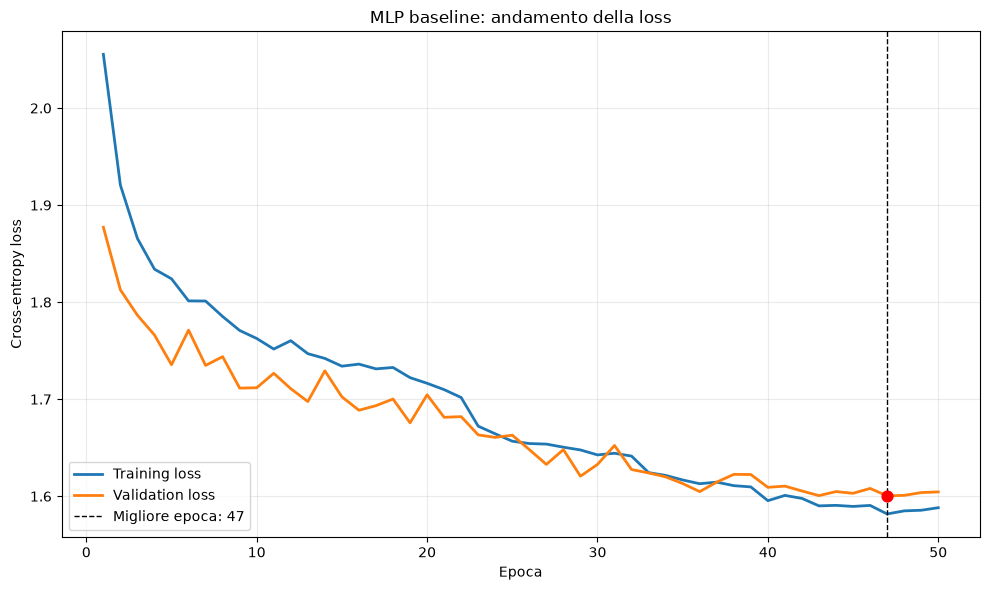

Grafico della loss salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\mlp_baseline_loss_curve.png


In [228]:
print(
    "Log CSV esistente:",
    MLP_CSV_LOG_PATH.exists()
)

assert MLP_CSV_LOG_PATH.exists()

csv_log_df = pd.read_csv(
    MLP_CSV_LOG_PATH
)

print(
    "Righe nel CSV:",
    len(csv_log_df)
)

print(
    "Colonne nel CSV:"
)

print(
    csv_log_df.columns)

assert len(csv_log_df) == mlp_epochs_completed

required_csv_columns = {
    "epoch",
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
}

assert required_csv_columns.issubset(
    set(csv_log_df.columns)
)

print(
    "Log CSV verificato ")

plt.figure(figsize=(10, 6))

plt.plot(
    mlp_history_df["epoch"],
    mlp_history_df["loss"],
    label="Training loss",
    linewidth=2
)

plt.plot(
    mlp_history_df["epoch"],
    mlp_history_df["val_loss"],
    label="Validation loss",
    linewidth=2
)

plt.axvline(
    x=best_epoch_number,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Migliore epoca: {best_epoch_number}"
)

plt.scatter(
    best_epoch_number,
    best_val_loss,
    color="red",
    s=60,
    zorder=5
)

plt.title(
    "MLP baseline: andamento della loss"
)

plt.xlabel("Epoca")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

MLP_LOSS_CURVE_PATH = (
    FIGURES_DIR
    / "mlp_baseline_loss_curve.png"
)

plt.savefig(
    MLP_LOSS_CURVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Grafico della loss salvato in:"
)

print(MLP_LOSS_CURVE_PATH)


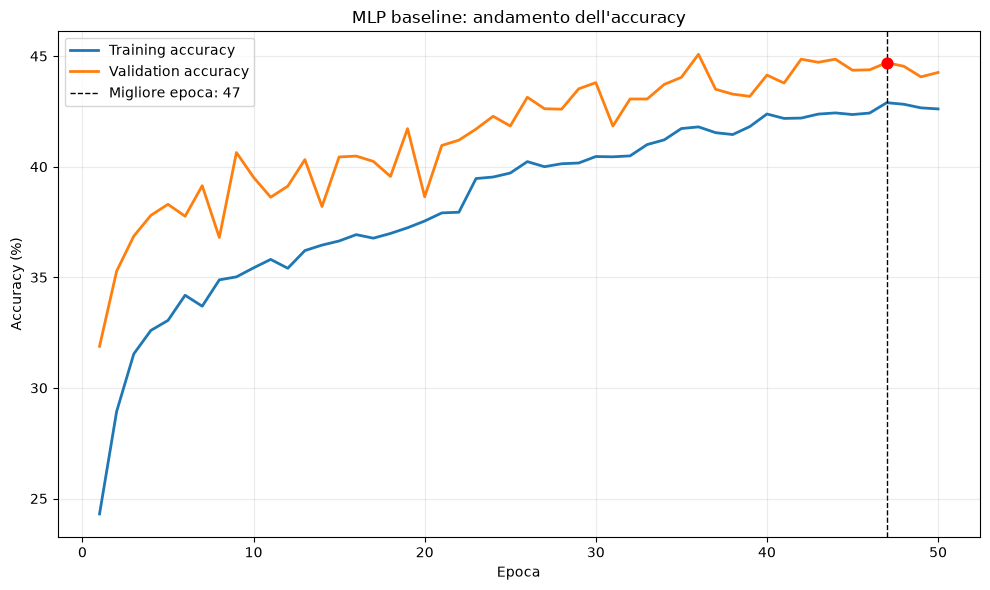

Grafico dell'accuracy salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\mlp_baseline_accuracy_curve.png


In [229]:
plt.figure(figsize=(10, 6))

plt.plot(
    mlp_history_df["epoch"],
    mlp_history_df["accuracy"] * 100,
    label="Training accuracy",
    linewidth=2
)

plt.plot(
    mlp_history_df["epoch"],
    mlp_history_df["val_accuracy"] * 100,
    label="Validation accuracy",
    linewidth=2
)

plt.axvline(
    x=best_epoch_number,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Migliore epoca: {best_epoch_number}"
)

plt.scatter(
    best_epoch_number,
    best_epoch_val_accuracy * 100,
    color="red",
    s=60,
    zorder=5
)

plt.title(
    "MLP baseline: andamento dell'accuracy"
)

plt.xlabel("Epoca")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

MLP_ACCURACY_CURVE_PATH = (
    FIGURES_DIR
    / "mlp_baseline_accuracy_curve.png"
)

plt.savefig(
    MLP_ACCURACY_CURVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Grafico dell'accuracy salvato in:"
)

print(MLP_ACCURACY_CURVE_PATH)

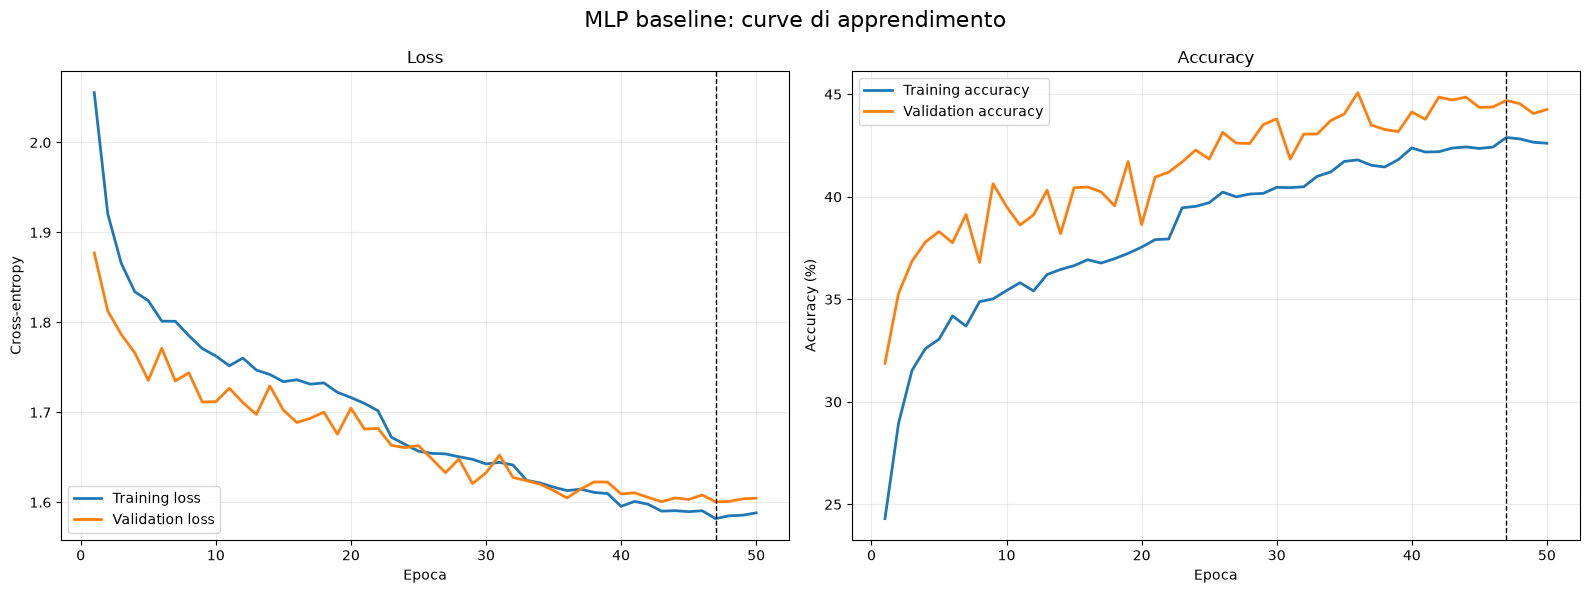

Grafico combinato salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\mlp_baseline_learning_curves.png


In [ ]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 6)
)

axes[0].plot(
    mlp_history_df["epoch"],
    mlp_history_df["loss"],
    label="Training loss",
    linewidth=2
)

axes[0].plot(
    mlp_history_df["epoch"],
    mlp_history_df["val_loss"],
    label="Validation loss",
    linewidth=2
)

axes[0].axvline(
    best_epoch_number,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    mlp_history_df["epoch"],
    mlp_history_df["accuracy"] * 100,
    label="Training accuracy",
    linewidth=2
)

axes[1].plot(
    mlp_history_df["epoch"],
    mlp_history_df["val_accuracy"] * 100,
    label="Validation accuracy",
    linewidth=2
)

axes[1].axvline(
    best_epoch_number,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.suptitle(
    "MLP baseline: curve di apprendimento",
    fontsize=16
)

plt.tight_layout()

MLP_COMBINED_CURVES_PATH = (
    FIGURES_DIR
    / "mlp_baseline_learning_curves.png"
)

plt.savefig(
    MLP_COMBINED_CURVES_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Grafico combinato salvato in:"
)

print(MLP_COMBINED_CURVES_PATH)



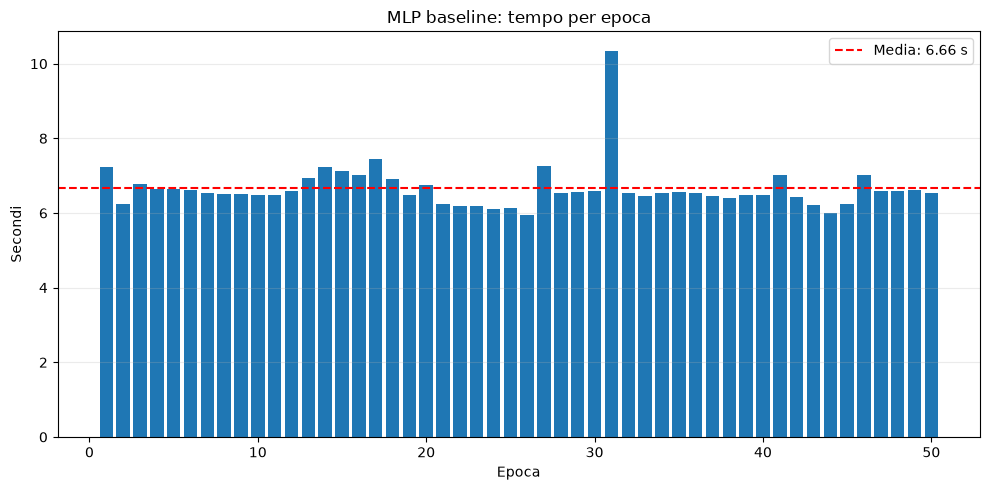

Grafico dei tempi salvato in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\figures\mlp_baseline_epoch_times.png
Valutazione descrittiva: gap contenuto


In [234]:
plt.figure(figsize=(10, 5))

plt.bar(
    mlp_history_df["epoch"],
    mlp_history_df["epoch_time_seconds"]
)

plt.axhline(
    y=average_epoch_time,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Media: "
        f"{average_epoch_time:.2f} s"
    )
)

plt.title(
    "MLP baseline: tempo per epoca"
)

plt.xlabel("Epoca")
plt.ylabel("Secondi")
plt.legend()
plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

MLP_EPOCH_TIME_PATH = (
    FIGURES_DIR
    / "mlp_baseline_epoch_times.png"
)

plt.savefig(
    MLP_EPOCH_TIME_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Grafico dei tempi salvato in:"
)

print(MLP_EPOCH_TIME_PATH)

if accuracy_generalization_gap < 0.03:
    overfitting_assessment = (
        "gap contenuto"
    )

elif accuracy_generalization_gap < 0.08:
    overfitting_assessment = (
        "gap moderato"
    )

else:
    overfitting_assessment = (
        "gap elevato, possibile overfitting"
    )

print(
    "Valutazione descrittiva:",
    overfitting_assessment
)

In [239]:
mlp_training_results_df = pd.DataFrame({
    "metric": [
        "Epoche completate",
        "Migliore epoca per val_loss",
        "Training loss alla migliore epoca",
        "Validation loss minima",
        "Training accuracy alla migliore epoca",
        "Validation accuracy alla migliore epoca",
        "Validation accuracy massima",
        "Generalization gap accuracy",
        "Tempo totale, secondi",
        "Tempo medio per epoca, secondi",
        "Numero parametri"
    ],

    "value": [
        mlp_epochs_completed,
        best_epoch_number,
        best_epoch_train_loss,
        best_val_loss,
        best_epoch_train_accuracy,
        best_epoch_val_accuracy,
        maximum_val_accuracy,
        accuracy_generalization_gap,
        mlp_training_elapsed_time,
        average_epoch_time,
        mlp_model.count_params()
    ]
})

mlp_training_results_df


MLP_TRAINING_RESULTS_PATH = (
    METRICS_DIR
    / "mlp_baseline_training_results.csv"
)

mlp_training_results_df.to_csv(
    MLP_TRAINING_RESULTS_PATH,
    index=False
)

print(
    "Tabella dei risultati salvata in:"
)

print(MLP_TRAINING_RESULTS_PATH)

Tabella dei risultati salvata in:
c:\Users\Msi\Desktop\machine-learing\progetto_cifar10-new\results\metrics\mlp_baseline_training_results.csv


In [243]:
mlp_training_config[
    "training_started"
] = True

mlp_training_config[
    "training_completed"
] = True

mlp_training_config[
    "epochs_completed"
] = int(
    mlp_epochs_completed
)

mlp_training_config[
    "best_epoch"
] = int(
    best_epoch_number
)

mlp_training_config[
    "test_set_used"
] = False

with open(
    MLP_TRAINING_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        mlp_training_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    "Configurazione del training aggiornata."
)



Configurazione del training aggiornata.


In [249]:
expected_training_files = [
    MLP_BEST_MODEL_PATH,
    MLP_FINAL_MODEL_PATH,
    MLP_CSV_LOG_PATH,
    MLP_HISTORY_CSV_PATH,
    MLP_TRAINING_SUMMARY_PATH,
    MLP_TRAINING_RESULTS_PATH,
    MLP_LOSS_CURVE_PATH,
    MLP_ACCURACY_CURVE_PATH,
    MLP_COMBINED_CURVES_PATH,
    MLP_EPOCH_TIME_PATH
]

if MLP_LEARNING_RATE_PATH is not None:
    expected_training_files.append(
        MLP_LEARNING_RATE_PATH
    )

print(
    "Controllo degli artefatti generati:\n"
)

for file_path in expected_training_files:
    exists = file_path.exists()

    size = (
        file_path.stat().st_size
        if exists
        else 0
    )

    print(
        f"{file_path.name:<48} "
        f"{'OK' if exists else 'MANCANTE':<10} "
        f"{size:>12} byte"
    )

NameError: name 'MLP_TRAINING_SUMMARY_PATH' is not defined

In [248]:
phase_3c_checks = {
    "training_history_exists": (
        mlp_history is not None
    ),

    "at_least_one_epoch_completed": (
        mlp_epochs_completed >= 1
    ),

    "epochs_within_limit": (
        mlp_epochs_completed <= MLP_MAX_EPOCHS
    ),

    "history_rows_correct": (
        len(mlp_history_df) == mlp_epochs_completed
    ),

    "epoch_times_correct": (
        len(epoch_times) == mlp_epochs_completed
    ),

    "best_epoch_valid": (
        1 <= best_epoch_number <= mlp_epochs_completed
    ),

    "best_validation_loss_finite": bool(
        np.isfinite(best_val_loss)
    ),

    "best_validation_accuracy_valid": (
        0.0 <= best_epoch_val_accuracy <= 1.0
    ),

    "checkpoint_exists": (
        MLP_BEST_MODEL_PATH.exists()
    ),

    "final_model_exists": (
        MLP_FINAL_MODEL_PATH.exists()
    ),

    "best_model_reloadable": (
        hasattr(mlp_best_model, "count_params")
        and mlp_best_model.count_params() == 1707274
    ),

    "checkpoint_loss_matches_history": bool(
        np.isclose(
            float(restored_validation_loss),
            float(best_val_loss),
            rtol=1e-4,
            atol=1e-4
        )
    ) if "restored_validation_loss" in globals() else False,

    "csv_log_exists": (
        MLP_CSV_LOG_PATH.exists()
    ),

    "complete_history_saved": (
        MLP_HISTORY_CSV_PATH.exists()
    ),

    "training_summary_saved": (
        MLP_TRAINING_SUMMARY_PATH.exists()
    ),

    "training_results_saved": (
        MLP_TRAINING_RESULTS_PATH.exists()
    ),

    "loss_curve_saved": (
        MLP_LOSS_CURVE_PATH.exists()
    ),

    "accuracy_curve_saved": (
        MLP_ACCURACY_CURVE_PATH.exists()
    ),

    "combined_curves_saved": (
        MLP_COMBINED_CURVES_PATH.exists()
    ),

    "epoch_time_curve_saved": (
        MLP_EPOCH_TIME_PATH.exists()
    ),

    "test_set_not_used": (
        mlp_training_summary["test_set_used"] is False
    )
}

for check_name, check_result in phase_3c_checks.items():
    status = "SUPERATO" if check_result else "NON SUPERATO"
    print(f"{check_name:<46} -> {status}")

assert all(phase_3c_checks.values())

print("\nFASE 3, BLOCCO C, COMPLETATO CORRETTAMENTE.")

NameError: name 'MLP_TRAINING_SUMMARY_PATH' is not defined

## Addestramento della MLP baseline

La MLP baseline è stata addestrata utilizzando il training set di
45.000 immagini e monitorata mediante un validation set indipendente
di 5.000 immagini.

L'addestramento prevedeva un massimo di 50 epoche, mini-batch da 64
esempi e l'ottimizzatore Adam con learning rate iniziale pari a 0,001.

La validation loss è stata utilizzata come criterio per Model
Checkpoint, ReduceLROnPlateau ed Early Stopping. Il modello
corrispondente alla validation loss minima è stato salvato nel formato
Keras.

Il training è terminato dopo [NUMERO] epoche. La migliore validation
loss è stata osservata all'epoca [EPOCA], con training accuracy pari a
[TRAIN ACCURACY] e validation accuracy pari a [VALIDATION ACCURACY].

Il generalization gap alla migliore epoca è risultato pari a
[GAP]. L'andamento congiunto delle curve di training e validation è
stato utilizzato per valutare l'eventuale presenza di overfitting.

La durata complessiva dell'addestramento è stata pari a [TEMPO]
minuti, mentre il tempo medio per epoca è stato pari a [TEMPO EPOCA]
secondi.

Il test set non è stato utilizzato durante l'addestramento o la scelta
della migliore epoca.

# Fase 3, Blocco D: valutazione approfondita della MLP

In questo blocco il miglior checkpoint della MLP viene analizzato
utilizzando esclusivamente il validation set.

L'analisi comprende:

- accuracy complessiva;
- precision, recall e F1-score per classe;
- macro average e weighted average;
- matrice di confusione assoluta;
- matrice di confusione normalizzata;
- confusioni più frequenti;
- distribuzione della confidenza;
- esempi classificati correttamente;
- esempi classificati erroneamente;
- errori commessi con elevata confidenza.

Il test set resta escluso e sarà utilizzato soltanto dopo il confronto
e il congelamento dei modelli finali.
``